# Лабораторна робота № 10. Математична морфологія бінарних та напівтонових зображень

### Мета: Дослідити теоретичні засади математичної морфології як інструменту нелінійної просторової обробки зображень, опанувати геометричні операції над множинами пікселів (ерозію, діляцію, морфологічне відкриття та закриття), вивчити вплив форми й розміру структуруючого елемента на структурну фільтрацію шумів та сегментацію, а також реалізувати конвеєри виділення контурів за допомогою морфологічного градієнта та компенсації нерівномірного фону за допомогою перетворень Top-Hat і Black-Hat.

#### *Варіант 2 (№ 22 у списку: $22 - 20 = 2$)*

### <div align="right">Виконав: Яцентюк Євгеній, група: КІ-24-1</div>
<div align="right">
  <a href="https://github.com/kefir4ikk"><b>GitHub</b></a>
</div>

## 1. Імпорт бібліотек та налаштування стилю відображення

In [1]:
import os
import csv
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import ndimage

os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#2b2b2b'
plt.rcParams['axes.linewidth'] = 1.0
plt.rcParams['grid.color'] = '#cccccc'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6

import scipy, matplotlib
print(f"NumPy: {np.__version__} | OpenCV: {cv2.__version__} | SciPy: {scipy.__version__} | Matplotlib: {matplotlib.__version__}")

NumPy: 2.5.3 | OpenCV: 5.0.0 | SciPy: 1.18.1 | Matplotlib: 3.11.2


## 2. Параметри варіанта 2 та постановка завдання

**Індивідуальне завдання (варіант 2):**

| Прикладна задача | Структуруючий елемент $B$ | $N_{iter}$ | Конвеєр | Контрольований показник |
|:-:|:-:|:-:|:-:|:-:|
| Дефектоскопія доріжок друкованих плат | `MORPH_RECT`, $5\times5$ | 1 | `Closing -> Black-Hat` | Виявлення розривів провідників |

**Основні операції** (для бінарної множини $A$ та структуруючого елемента $B$):

$$A\ominus B=\{z\mid B_z\subseteq A\},\quad A\oplus B=\{z\mid \hat B_z\cap A\ne\emptyset\},\quad A\circ B=(A\ominus B)\oplus B,\quad A\bullet B=(A\oplus B)\ominus B,$$

$$G(A)=(A\oplus B)-(A\ominus B),\qquad \mathrm{TH}(I)=I-I\circ B,\qquad \mathrm{BH}(I)=I\bullet B-I.$$

**Чому «закриття → чорний капелюх» потребує уточнення.** Закриття ідемпотентне: $(I\bullet B)\bullet B=I\bullet B$. Отже, якщо застосувати Black-Hat **до вже закритого кадру** з тим самим $B$, результат тотожно нульовий: $\mathrm{BH}(I\bullet B)=(I\bullet B)\bullet B-I\bullet B=0$. Тому конвеєр реалізується як **закриття вихідного кадру («віртуальний ремонт» плати) та різниця закритого й вихідного**: $D=I\bullet B-I$ — це і є Black-Hat, тобто карта дефектів. Це перевіряється в роботі явно.

**Фізика виявлення розривів.** Мідні провідники яскраві, підкладка темна, розрив — темний «провал» усередині яскравої доріжки. Закриття квадратним елементом $K\times K$ заповнює темну область, якщо в неї **не вміщується жодна копія $B$**. Для розриву через усю ширину доріжки це означає ширину розриву $w\le K-1=4$ px. Розриви $w\ge K$ закриття не заповнює, і Black-Hat їх не бачить. Для $N_{iter}$ ітерацій прямокутний елемент $K\times K$ еквівалентний одному елементу розміру $(K-1)N_{iter}+1$ (для $K=5$, $N_{iter}=2$ — $9\times9$). Для розриву діагональної доріжки довжиною $L$ вздовж доріжки закриття заповнює його, якщо в смугу не вміщується жодна копія $B$. Смуга має ширину $L\sqrt2$ у координаті $x+y$, а елемент — екстент $e_B$ у цій координаті: $e=2(K-1)=8$ для квадрата $5\times5$, $6$ для еліпса, $4$ для хреста. Отже, розрив заповнюється при $L<e_B/\sqrt2$, тобто $L<5.66$ (RECT), $L<4.24$ (ELLIPSE), $L<2.83$ (CROSS): форма елемента має значення саме на косих структурах.

**Тестові сцени.** Програмно синтезується макет плати $400\times600$ (чотири горизонтальні доріжки шириною 10 px з квадратними контактними площадками та отворами, діагональна доріжка, пара доріжок з вузьким зазором 4 px) з **відомим набором дефектів**:

| ID | Тип | Розмір | ID | Тип | Розмір |
|:-:|:-:|:-:|:-:|:-:|:-:|
| D1 | розрив | 2 px | D7 | розрив | 8 px |
| D2 | розрив | 3 px | D8 | тріщина | 1 px |
| D3 | розрив | 4 px | D9 | пора (отвір) у міді | $\approx3$ px |
| D4 | розрив | 6 px | D10 | розрив діагональної доріжки (довжина вздовж доріжки) | 3 px |
| D5 | виїмка («миші укус») | $4\times3$ px | D11 | розрив діагональної доріжки (довжина вздовж доріжки) | 5 px |
| D6 | пора (отвір) у міді | $\approx3$ px | | | |

Бінарна сцена — маска міді з дефектами та точковими викидами міді («salt», залишки травлення поза доріжками). Напівтонова сцена — те саме зображення з нерівномірним освітленням (центр удвічі яскравіший за кути), шумом сенсора $\sigma=3$ і розмиттям країв. Еталонна («золота») плата без дефектів з іншою реалізацією шуму використовується для калібрування порога. Вузький зазор $4$ px між двома доріжками — **легітимна** структура, яку закриття теж заповнює (хибне спрацювання): її розмір є верхньою межею для $K$.

In [2]:
# --- Параметри варіанта 2
H_IMG, W_IMG = 400, 600
SE_SIZE, N_ITER = 5, 1
SE_SHAPE = cv2.MORPH_RECT

# --- Параметри макета плати
TRACK_Y, TRACK_W = [70, 150, 230, 310], 10
X0, X1 = 60, 540
PAD, HOLE = 16, 6
FP_X, FP_ROWS = (120, 320), ((360, 365), (370, 375))       # пара доріжок із зазором 4 px (рядки 366..369)
DIAG_START, DIAG_LEN, DIAG_W = (400, 330), 70.0, 8
U = np.array([1.0, 1.0]) / np.sqrt(2); V = np.array([1.0, -1.0]) / np.sqrt(2)

DEFECTS = [
    dict(id="D1", kind="break", track=0, x=200, w=2),
    dict(id="D2", kind="break", track=0, x=330, w=3),
    dict(id="D3", kind="break", track=0, x=450, w=4),
    dict(id="D4", kind="break", track=1, x=250, w=6),
    dict(id="D5", kind="notch", track=1, x=400, w=4, depth=3),
    dict(id="D6", kind="pinhole", track=2, x=180),
    dict(id="D7", kind="break", track=2, x=330, w=8),
    dict(id="D8", kind="break", track=3, x=260, w=1),
    dict(id="D9", kind="pinhole", track=3, x=430),
    dict(id="D10", kind="diag_break", t=25.0, w=3),
    dict(id="D11", kind="diag_break", t=55.0, w=5),
]

def diag_polygon(t, L, half_w=9):
    c = np.array(DIAG_START, float) + t * U
    return np.round([c - U * L / 2 + V * half_w, c + U * L / 2 + V * half_w, c + U * L / 2 - V * half_w, c - U * L / 2 - V * half_w]).astype(np.int32)

def build_clean_copper():
    m = np.zeros((H_IMG, W_IMG), np.uint8)
    for y in TRACK_Y:
        cv2.rectangle(m, (X0, y - 5), (X1, y + 4), 255, -1)
        for x in (X0, X1):
            cv2.rectangle(m, (x - PAD, y - PAD), (x + PAD - 1, y + PAD - 1), 255, -1)        # квадратна контактна площадка
            cv2.rectangle(m, (x - HOLE, y - HOLE), (x + HOLE - 1, y + HOLE - 1), 0, -1)      # монтажний отвір
    for (r0, r1) in FP_ROWS:
        cv2.rectangle(m, (FP_X[0], r0), (FP_X[1], r1), 255, -1)
    p0 = np.array(DIAG_START, float); p1 = p0 + DIAG_LEN * U
    cv2.line(m, tuple(int(v) for v in np.round(p0)), tuple(int(v) for v in np.round(p1)), 255, DIAG_W)
    return m

def defect_mask(clean, d):
    """Піксельна маска дефекту: мідь, яка видалена дефектом (еталон розмітки)."""
    m = np.zeros_like(clean)
    if d["kind"] == "break":
        y = TRACK_Y[d["track"]]; cv2.rectangle(m, (d["x"], y - 5), (d["x"] + d["w"] - 1, y + 4), 255, -1)
    elif d["kind"] == "notch":
        y = TRACK_Y[d["track"]]; cv2.rectangle(m, (d["x"], y - 5), (d["x"] + d["w"] - 1, y - 5 + d["depth"] - 1), 255, -1)
    elif d["kind"] == "pinhole":
        y = TRACK_Y[d["track"]]; cv2.circle(m, (d["x"], y), 1, 255, -1)
    elif d["kind"] == "diag_break":
        cv2.fillPoly(m, [diag_polygon(d["t"], d["w"])], 255)
    return cv2.bitwise_and(m, clean)

def generate_pcb_scenes(seed=5):
    """Бінарна та напівтонова сцени плати: еталон, дефекти, точкові викиди міді, золота плата."""
    clean = build_clean_copper()
    for d in DEFECTS: d["mask"] = defect_mask(clean, d)
    defects_all = np.zeros_like(clean)
    for d in DEFECTS: defects_all |= d["mask"]
    board = cv2.bitwise_and(clean, cv2.bitwise_not(defects_all))
    # точкові викиди міді ('salt'): далі ніж 10 px від міді та поза зоною вузького зазору
    rng = np.random.default_rng(seed)
    dist = cv2.distanceTransform(cv2.bitwise_not(clean), cv2.DIST_L2, 5)
    n_debris, specks = 0, board.copy()
    while n_debris < 40:
        x, y = int(rng.integers(15, W_IMG - 15)), int(rng.integers(15, H_IMG - 15))
        if dist[y, x] > 10:
            cv2.circle(specks, (x, y), int(rng.integers(1, 3)), 255, -1); n_debris += 1
    return clean, board, specks

def render_gray(copper, seed):
    """Напівтонова сцена: мідь 190, підкладка 45, розмиття країв, освітлення (центр ×1.0, кути ≈ ×0.63), шум сенсора σ = 3."""
    base = cv2.GaussianBlur(np.where(copper > 0, 190.0, 45.0).astype(np.float32), (0, 0), 0.8)
    yy, xx = np.mgrid[0:H_IMG, 0:W_IMG]
    g = 0.5 + 0.5 * np.exp(-((xx - W_IMG / 2) ** 2 + (yy - H_IMG / 2) ** 2) / (2 * 220.0 ** 2))
    return np.clip(np.rint(base * g + np.random.default_rng(seed).normal(0, 3.0, (H_IMG, W_IMG))), 0, 255).astype(np.uint8), g

clean_mask, board_mask, img_binary_raw = generate_pcb_scenes()
img_gray_raw, illum = render_gray(img_binary_raw, seed=12)
img_golden, _ = render_gray(clean_mask, seed=11)                 # золота плата без дефектів та викидів
fp_gap = np.zeros((H_IMG, W_IMG), np.uint8); fp_gap[FP_ROWS[0][1] + 1:FP_ROWS[1][0], FP_X[0]:FP_X[1] + 1] = 255
cv2.imwrite("data/binary_pcb_raw.png", img_binary_raw); cv2.imwrite("data/grayscale_pcb_uneven.png", img_gray_raw)
cv2.imwrite("data/pcb_clean_copper.png", clean_mask); cv2.imwrite("data/grayscale_pcb_golden.png", img_golden)
print(f"Сцени {W_IMG}x{H_IMG} збережено. Мідь еталона: {cv2.countNonZero(clean_mask)} px; після дефектів та викидів: {cv2.countNonZero(img_binary_raw)} px")
print("Дефекти (площа еталонної маски, px): " + ", ".join(f"{d['id']}={cv2.countNonZero(d['mask'])}" for d in DEFECTS))
print(f"Освітлення: діапазон множника {illum.min():.2f} ... {illum.max():.2f}; яскравість напівтонового кадру [{img_gray_raw.min()}, {img_gray_raw.max()}]")

Сцени 600x400 збережено. Мідь еталона: 28060 px; після дефектів та викидів: 28058 px
Дефекти (площа еталонної маски, px): D1=20, D2=30, D3=40, D4=60, D5=12, D6=5, D7=80, D8=10, D9=5, D10=32, D11=52
Освітлення: діапазон множника 0.63 ... 1.00; яскравість напівтонового кадру [18, 197]


## 3. Структуруючі елементи

Створюються елементи $5\times5$ трьох форм. Кількість ненульових елементів визначає «силу» зондування: прямокутник $25$, еліпс $17$, хрест $9$ одиниць. Форма впливає на мінімальний розмір структури, яка ще вміщує елемент і тому не буде змінена (див. розділ 8).

СТРУКТУРУЮЧІ ЕЛЕМЕНТИ РОЗМІРОМ 5x5 ПІКСЕЛІВ
Прямокутний (MORPH_RECT) - елемент варіанта 2: 25 одиниць
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

Хрестоподібний (MORPH_CROSS): 9 одиниць
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]

Еліптичний (MORPH_ELLIPSE): 17 одиниць
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]



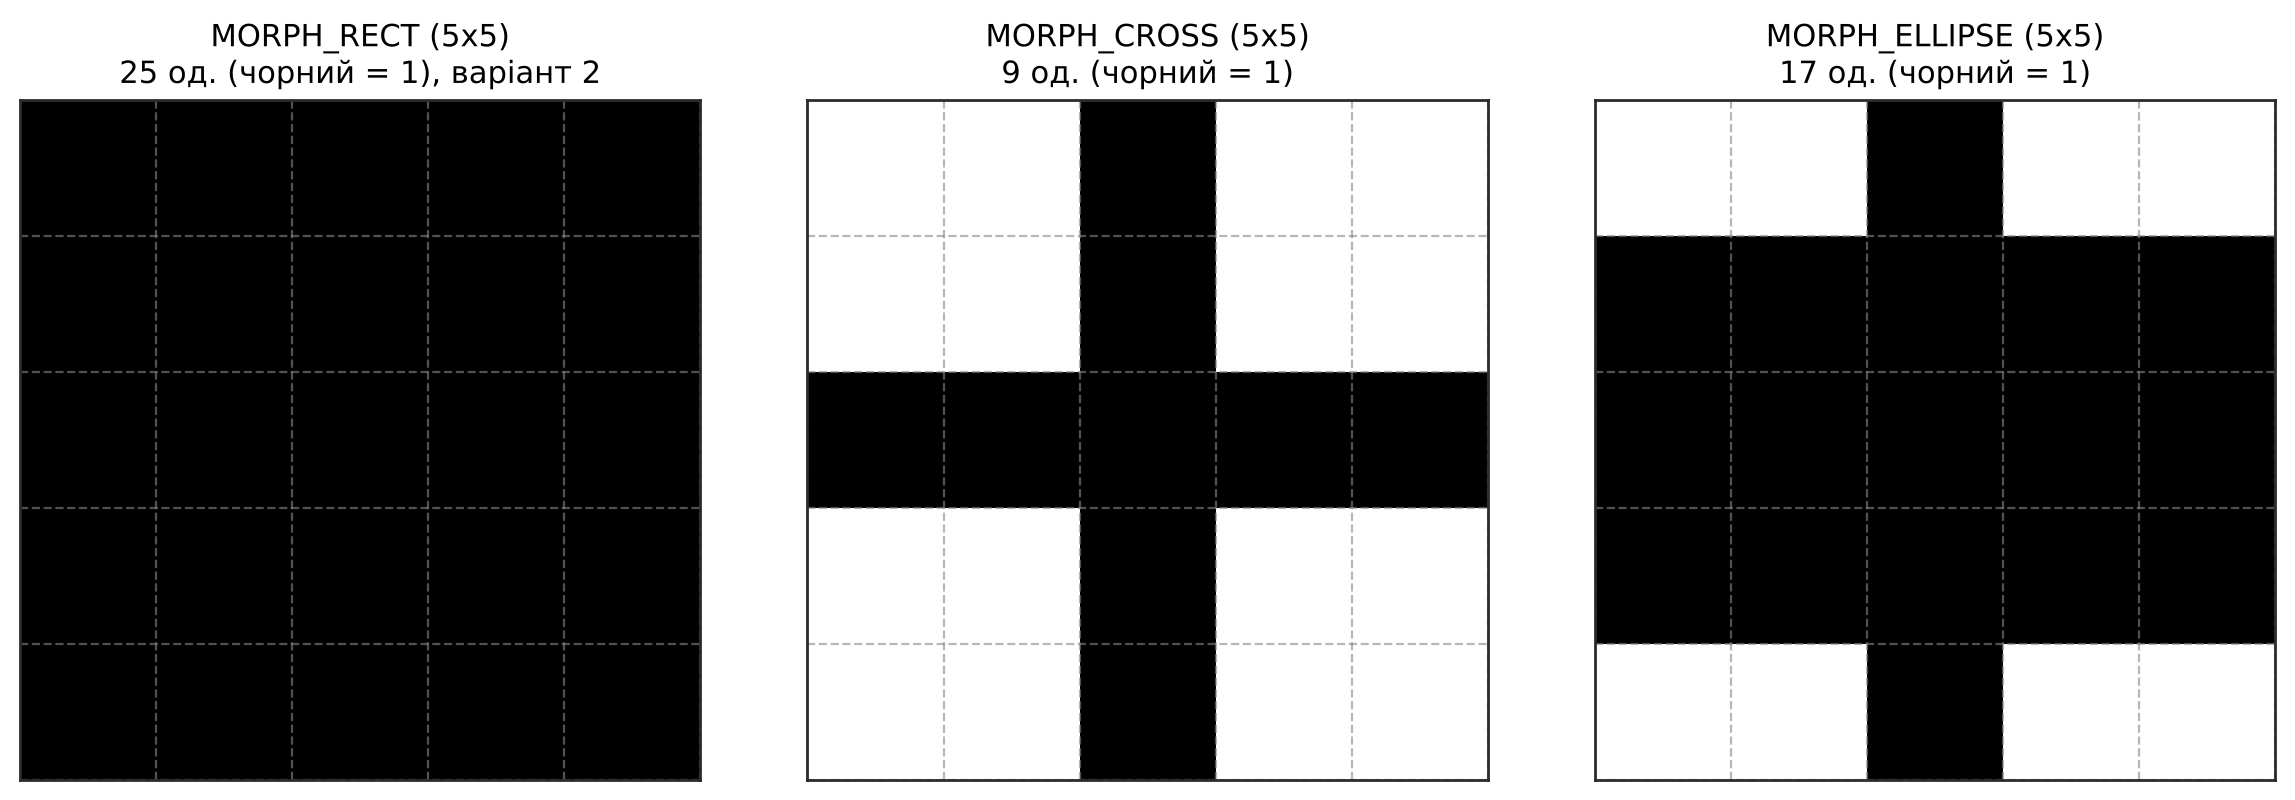

In [3]:
se_rect = cv2.getStructuringElement(cv2.MORPH_RECT, (SE_SIZE, SE_SIZE))
se_cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (SE_SIZE, SE_SIZE))
se_ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (SE_SIZE, SE_SIZE))
assert se_rect.sum() == SE_SIZE ** 2 and se_cross.sum() == 2 * SE_SIZE - 1
assert np.array_equal(se_rect, np.ones((SE_SIZE, SE_SIZE), np.uint8)) and np.array_equal(se_cross[SE_SIZE // 2], np.ones(SE_SIZE)) and np.array_equal(se_cross[:, SE_SIZE // 2], np.ones(SE_SIZE))
SE = se_rect                                                           # елемент варіанта 2

print("=" * 70)
print(f"СТРУКТУРУЮЧІ ЕЛЕМЕНТИ РОЗМІРОМ {SE_SIZE}x{SE_SIZE} ПІКСЕЛІВ")
print("=" * 70)
for nm, se in [("Прямокутний (MORPH_RECT) - елемент варіанта 2", se_rect), ("Хрестоподібний (MORPH_CROSS)", se_cross), ("Еліптичний (MORPH_ELLIPSE)", se_ellipse)]:
    print(f"{nm}: {int(se.sum())} одиниць\n{se}\n")

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, se, nm in zip(axes, [se_rect, se_cross, se_ellipse], ["MORPH_RECT", "MORPH_CROSS", "MORPH_ELLIPSE"]):
    ax.imshow(se, cmap='gray_r', interpolation='nearest', vmin=0, vmax=1)
    ax.set_xticks(np.arange(-0.5, SE_SIZE, 1), minor=True); ax.set_yticks(np.arange(-0.5, SE_SIZE, 1), minor=True)
    ax.grid(which='minor', color='#888888', lw=0.8); ax.tick_params(which='both', length=0, labelbottom=False, labelleft=False)
    ax.set_title(f"{nm} ({SE_SIZE}x{SE_SIZE})\n{int(se.sum())} од. (чорний = 1)" + (", варіант 2" if nm == "MORPH_RECT" else ""), fontsize=11)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.03, top=0.84, wspace=0.08)
plt.savefig("figures/structuring_elements.png", dpi=200)
plt.show()

## 4. Ерозія та діляція бінарної сцени

Операції виконуються `cv2.erode` / `cv2.dilate` з $N_{iter}=1$ (параметр варіанта). Перевіряються: збіг із `scipy.ndimage.binary_erosion/dilation` (для ерозії межа кадру вважається переднім планом, як в OpenCV); еквівалентність $N$ ітерацій одному більшому елементу, $\ominus^{N}_{5\times5}=\ominus_{9\times9}$ при $N=2$; двоїстість $A\ominus B=\overline{\overline A\oplus B}$; зміна площі.

ВПЛИВ ЕРОЗІЇ ТА ДІЛЯЦІЇ НА ПЛОЩУ ОБ'ЄКТІВ (SE = RECT 5x5, N = 1)
Початкова площа:     28058 px; компонентів зв'язності (8-зв.): 54
Після ерозії:        15648 px (зміна -44.2 %); компонентів: 17
Після діляції:       42074 px (зміна +50.0 %); компонентів: 47
Перевірки: збіг із scipy.ndimage; N = 2 для 5x5 ≡ один елемент 9x9; двоїстість ерозії та діляції — виконано


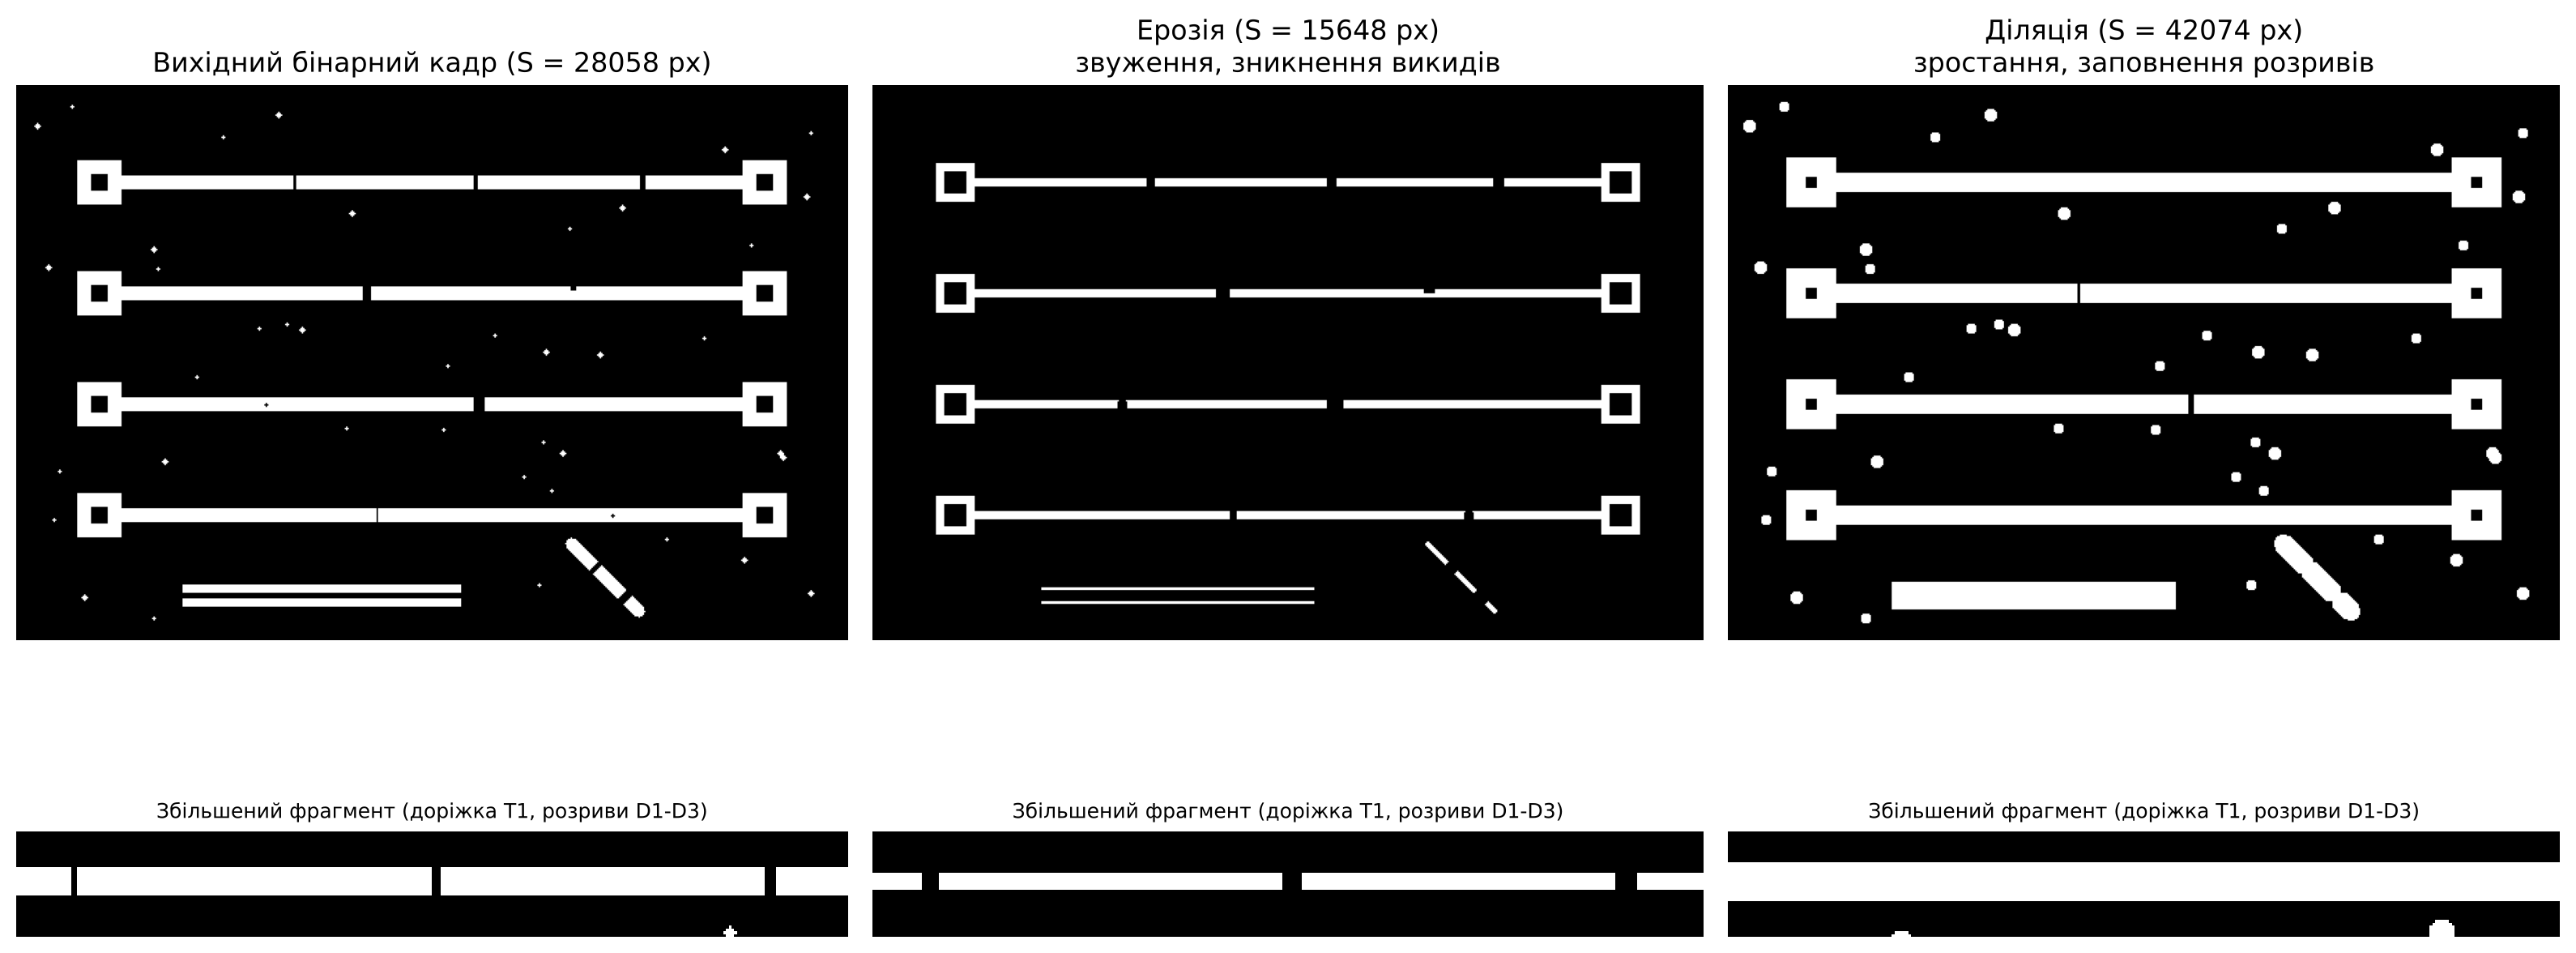

In [4]:
A = img_binary_raw
img_eroded = cv2.erode(A, SE, iterations=N_ITER)
img_dilated = cv2.dilate(A, SE, iterations=N_ITER)

# --- Перевірки
assert np.array_equal(img_eroded > 0, ndimage.binary_erosion(A > 0, structure=SE.astype(bool), border_value=1))
assert np.array_equal(img_dilated > 0, ndimage.binary_dilation(A > 0, structure=SE.astype(bool), border_value=0))
se9 = cv2.getStructuringElement(cv2.MORPH_RECT, (2 * (SE_SIZE - 1) + 1,) * 2)
assert np.array_equal(cv2.erode(A, SE, iterations=2), cv2.erode(A, se9)) and np.array_equal(cv2.dilate(A, SE, iterations=2), cv2.dilate(A, se9))
dual = cv2.bitwise_not(cv2.dilate(cv2.bitwise_not(A), SE))
assert np.array_equal(img_eroded[3:-3, 3:-3], dual[3:-3, 3:-3])

area_orig, area_er, area_di = cv2.countNonZero(A), cv2.countNonZero(img_eroded), cv2.countNonZero(img_dilated)
n_raw = cv2.connectedComponents(A, connectivity=8)[0] - 1
n_er = cv2.connectedComponents(img_eroded, connectivity=8)[0] - 1
n_di = cv2.connectedComponents(img_dilated, connectivity=8)[0] - 1
print("=" * 84)
print(f"ВПЛИВ ЕРОЗІЇ ТА ДІЛЯЦІЇ НА ПЛОЩУ ОБ'ЄКТІВ (SE = RECT {SE_SIZE}x{SE_SIZE}, N = {N_ITER})")
print("=" * 84)
print(f"Початкова площа:   {area_orig:7d} px; компонентів зв'язності (8-зв.): {n_raw}")
print(f"Після ерозії:      {area_er:7d} px (зміна {100 * (area_er / area_orig - 1):+.1f} %); компонентів: {n_er}")
print(f"Після діляції:     {area_di:7d} px (зміна {100 * (area_di / area_orig - 1):+.1f} %); компонентів: {n_di}")
print("Перевірки: збіг із scipy.ndimage; N = 2 для 5x5 ≡ один елемент 9x9; двоїстість ерозії та діляції — виконано")
print("=" * 84)

zr = (slice(52, 90), slice(180, 480))                                     # фрагмент із розривами D1-D3
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for j, (im, ttl) in enumerate([(A, f"Вихідний бінарний кадр (S = {area_orig} px)"), (img_eroded, f"Ерозія (S = {area_er} px)\nзвуження, зникнення викидів"),
                               (img_dilated, f"Діляція (S = {area_di} px)\nзростання, заповнення розривів")]):
    axes[0, j].imshow(im, cmap='gray', vmin=0, vmax=255); axes[0, j].set_title(ttl); axes[0, j].axis('off')
    axes[1, j].imshow(im[zr], cmap='gray', vmin=0, vmax=255, interpolation='nearest'); axes[1, j].set_title("Збільшений фрагмент (доріжка T1, розриви D1-D3)", fontsize=9); axes[1, j].axis('off')
plt.tight_layout()
plt.savefig("figures/erosion_dilation_comp.png", dpi=200)
plt.show()

## 5. Відкриття, закриття та аналіз зв'язних компонент

Конвеєр очищення бінарної маски: закриття (ремонт розривів ширини $\le K-1$ та пор) і відкриття (видалення точкових викидів міді). Перевіряються екстенсивність/антиекстенсивність $A\circ B\subseteq A\subseteq A\bullet B$ та ідемпотентність. Якість відновлення вимірюється індексом Жаккара $\mathrm{IoU}$ відносно еталонної маски міді. Кількість компонентів зв'язності показує, скільки розривів усунено (кожен усунутий розрив зливає два фрагменти доріжки в один), але вузький зазор між парою доріжок закриттям теж «замикається».

РЕЗУЛЬТАТИ МОРФОЛОГІЧНОЇ ОБРОБКИ БІНАРНОЇ СЦЕНИ
Зображення                           площа, px    IoU з еталоном  IoU без зони зазору   компонентів
Еталонна мідь (без дефектів)             28060            1.0000               1.0000             7
Сирий кадр (дефекти + викиди)            28058            0.9757               0.9742            54
Відкриття                                27644            0.9852               0.9843            17
Закриття                                 29042            0.9550               0.9810            47
Закриття -> Відкриття                    28694            0.9663               0.9936             8
----------------------------------------------------------------------------------------
Розрізи доріжок: 8 (D1, D2, D3, D4, D7, D8, D10, D11); усуваються закриттям 5x5: 6; лишаються: D4, D7
Фрагменти після відкриття без закриття: 17 (відкриття розрізає доріжки в місцях пор D6, D9: перемички міді вужчі за 5 px)
Прогноз кількості компонентів після кон

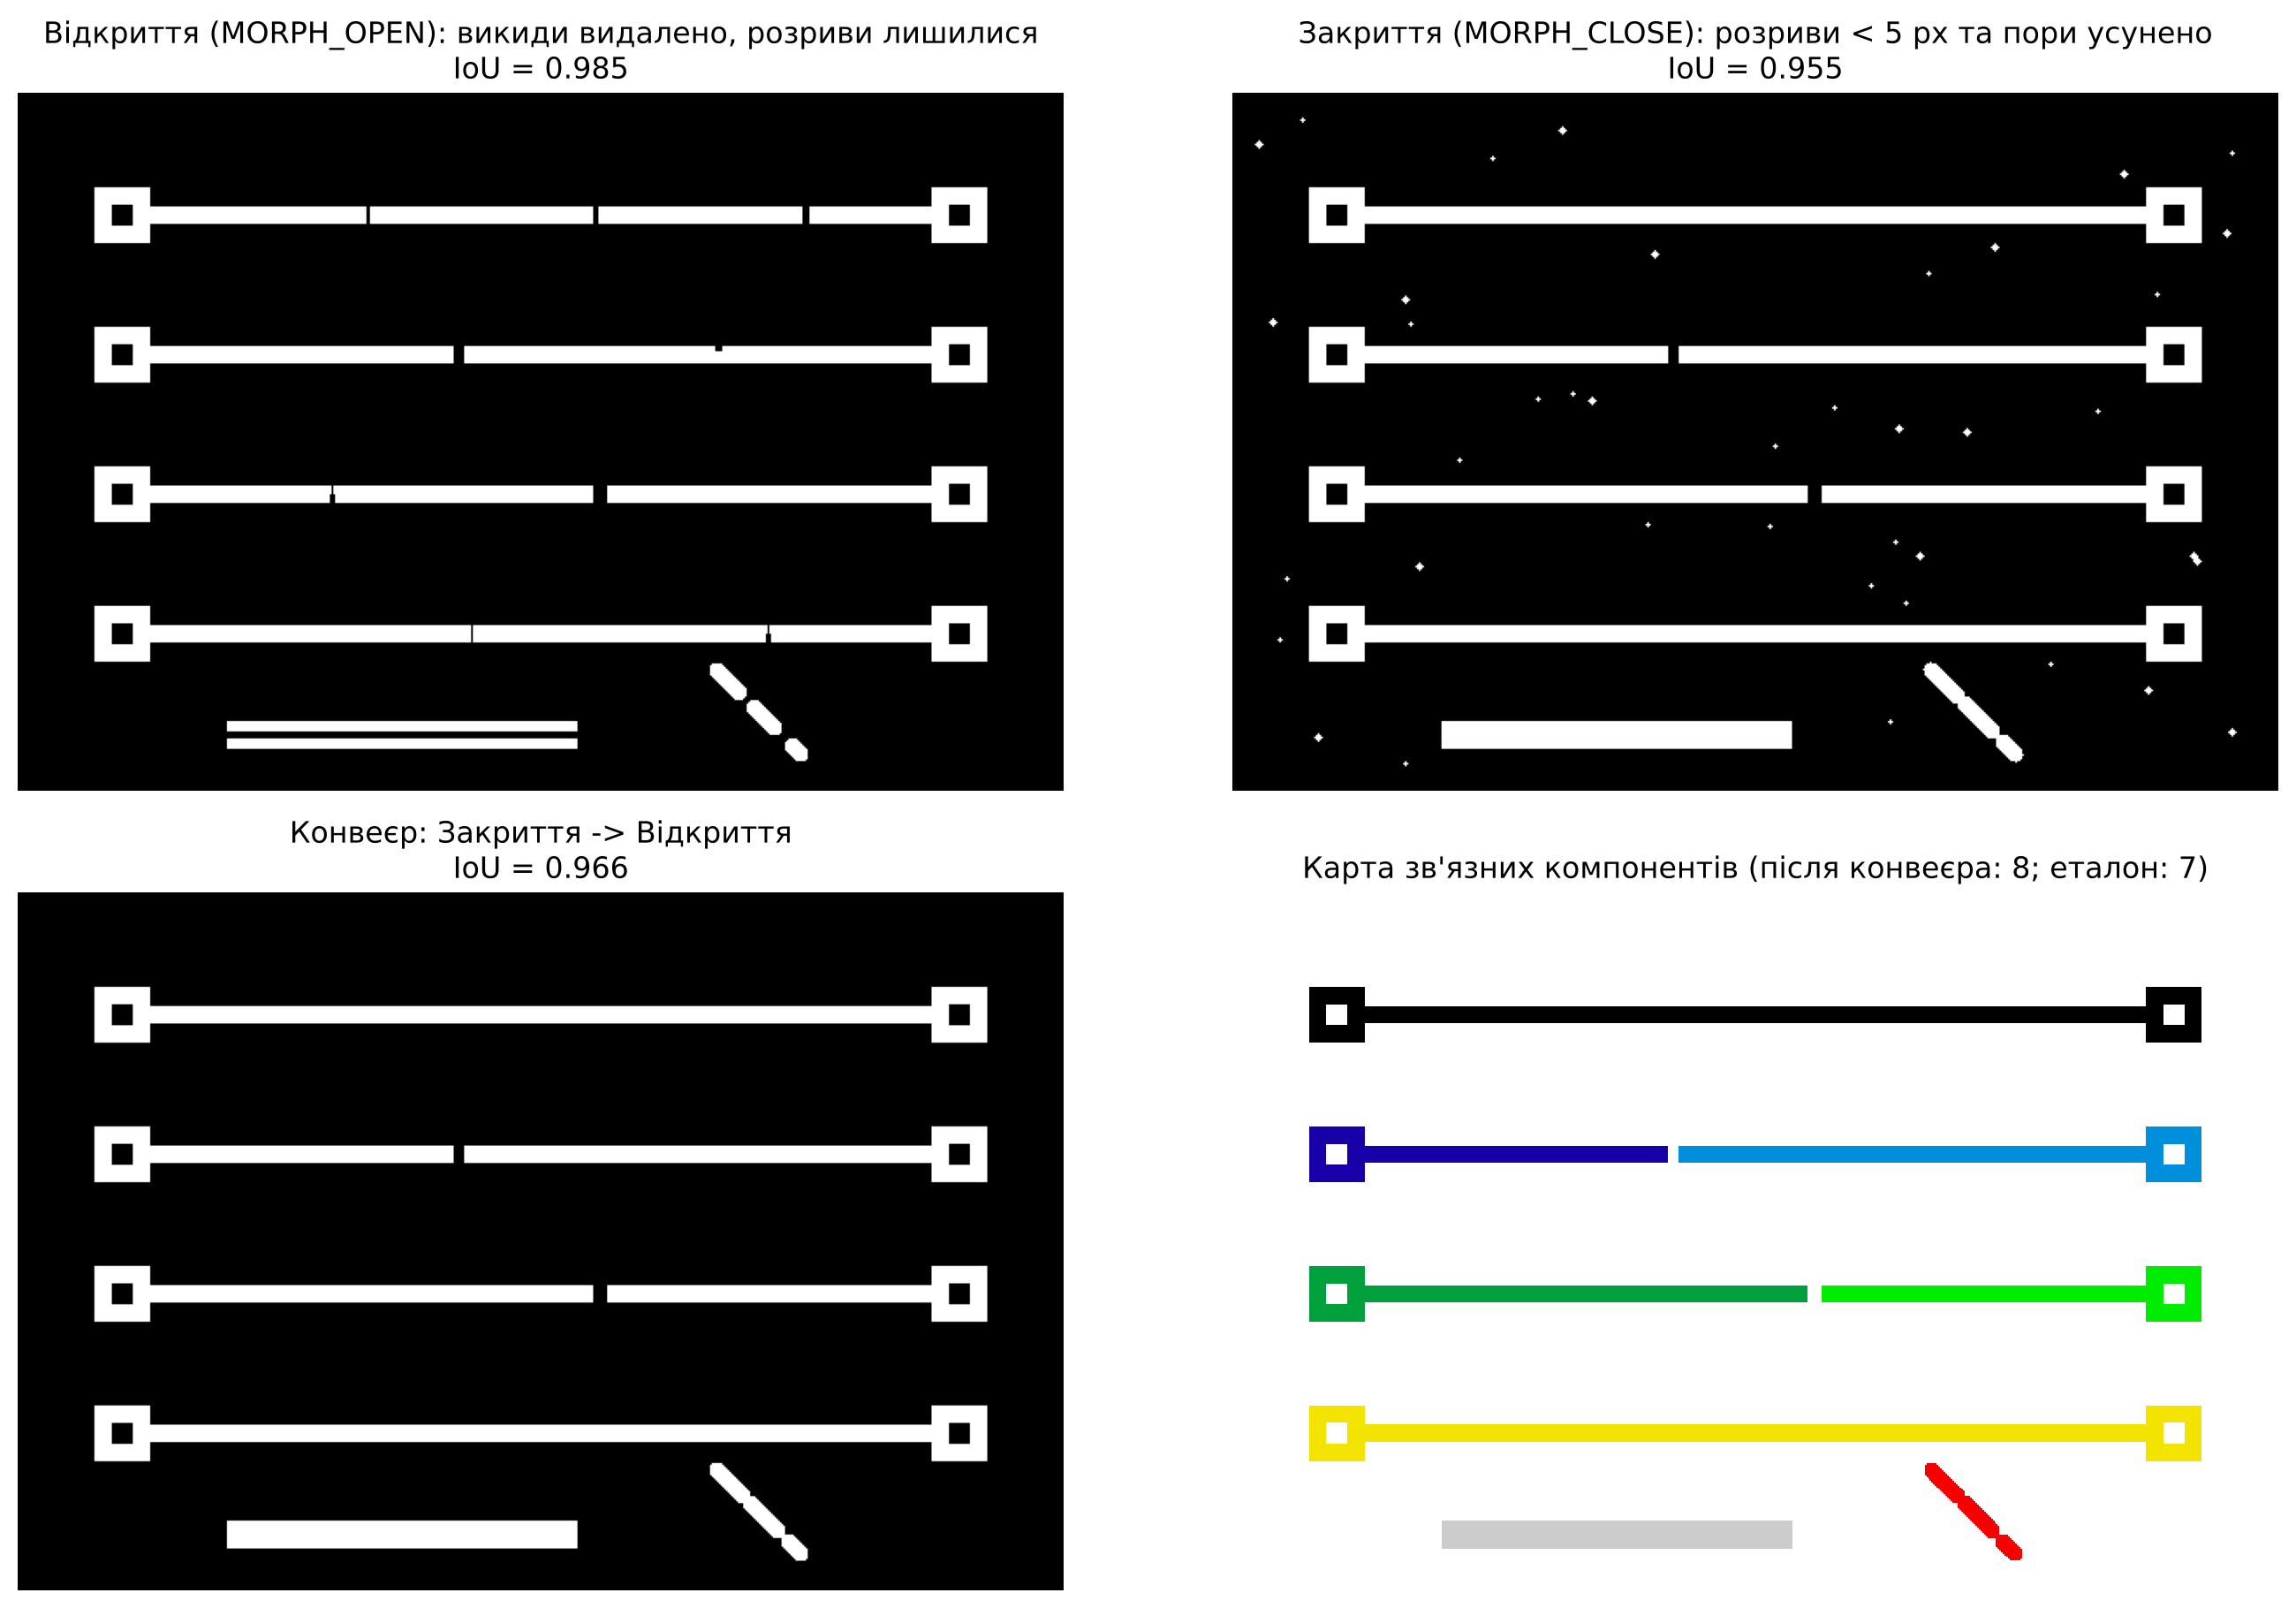

In [5]:
img_opened = cv2.morphologyEx(A, cv2.MORPH_OPEN, SE, iterations=N_ITER)
img_closed = cv2.morphologyEx(A, cv2.MORPH_CLOSE, SE, iterations=N_ITER)
img_pipeline = cv2.morphologyEx(img_closed, cv2.MORPH_OPEN, SE, iterations=N_ITER)           # Close -> Open

# --- Властивості операторів
assert np.all(img_opened <= A) and np.all(A <= img_closed)                                    # антиекстенсивність / екстенсивність
assert np.array_equal(cv2.morphologyEx(img_opened, cv2.MORPH_OPEN, SE), img_opened)           # ідемпотентність відкриття
assert np.array_equal(cv2.morphologyEx(img_closed, cv2.MORPH_CLOSE, SE), img_closed)          # ідемпотентність закриття

def iou(a, b):
    a, b = a > 0, b > 0; return float(np.logical_and(a, b).sum() / np.logical_or(a, b).sum())
def n_comp(m): return cv2.connectedComponents(m, connectivity=8)[0] - 1
excl = ~(cv2.dilate(fp_gap, np.ones((9, 9), np.uint8)) > 0)                                      # без зони вузького зазору
def iou_excl(a, b): return float(np.logical_and(a > 0, b > 0)[excl].sum() / np.logical_or(a > 0, b > 0)[excl].sum())

# Компоненти: еталон, сирий кадр, після відкриття (без викидів), після закриття, після конвеєра
comps = dict(clean=n_comp(clean_mask), raw=n_comp(A), opened=n_comp(img_opened), closed=n_comp(img_closed), pipeline=n_comp(img_pipeline))
n_labels, labels_map, stats, cents = cv2.connectedComponentsWithStats(img_pipeline, connectivity=8)

print("=" * 88)
print("РЕЗУЛЬТАТИ МОРФОЛОГІЧНОЇ ОБРОБКИ БІНАРНОЇ СЦЕНИ")
print("=" * 88)
print(f"{'Зображення':<34}{'площа, px':>12}{'IoU з еталоном':>18}{'IoU без зони зазору':>21}{'компонентів':>14}")
for nm, im, key in [("Еталонна мідь (без дефектів)", clean_mask, 'clean'), ("Сирий кадр (дефекти + викиди)", A, 'raw'), ("Відкриття", img_opened, 'opened'),
                    ("Закриття", img_closed, 'closed'), ("Закриття -> Відкриття", img_pipeline, 'pipeline')]:
    print(f"{nm:<34}{cv2.countNonZero(im):12d}{iou(im, clean_mask):18.4f}{iou_excl(im, clean_mask):21.4f}{comps[key]:14d}")
print("-" * 88)
def repairable(d):
    return (d["kind"] == "break" and d["w"] <= SE_SIZE - 1) or (d["kind"] == "diag_break" and d["w"] * np.sqrt(2) < 2 * (SE_SIZE - 1))
cuts = [d for d in DEFECTS if d["kind"] in ("break", "diag_break")]
unrep = [d["id"] for d in cuts if not repairable(d)]
pred_after = comps['clean'] + len(unrep) - 1                         # +1 фрагмент на кожен нерозірваний розрив, -1 хибне злиття пари доріжок
print(f"Розрізи доріжок: {len(cuts)} ({', '.join(d['id'] for d in cuts)}); усуваються закриттям {SE_SIZE}x{SE_SIZE}: {len(cuts) - len(unrep)}; лишаються: {', '.join(unrep)}")
print(f"Фрагменти після відкриття без закриття: {comps['opened']} (відкриття розрізає доріжки в місцях пор D6, D9: перемички міді вужчі за {SE_SIZE} px)")
print(f"Прогноз кількості компонентів після конвеєра: {comps['clean']} (еталон) + {len(unrep)} (нерозірвані) - 1 (хибне злиття зазору) = {pred_after}; виміряно: {comps['pipeline']}")
print(f"Площа міді: сирий {cv2.countNonZero(A)} px -> конвеєр {cv2.countNonZero(img_pipeline)} px; еталон {cv2.countNonZero(clean_mask)} px")
assert pred_after == comps['pipeline']
print("=" * 88)

fig, axes = plt.subplots(2, 2, figsize=(14, 9.2))
axes[0, 0].imshow(img_opened, cmap='gray'); axes[0, 0].set_title(f"Відкриття (MORPH_OPEN): викиди видалено, розриви лишилися\nIoU = {iou(img_opened, clean_mask):.3f}")
axes[0, 1].imshow(img_closed, cmap='gray'); axes[0, 1].set_title(f"Закриття (MORPH_CLOSE): розриви < {SE_SIZE} px та пори усунено\nIoU = {iou(img_closed, clean_mask):.3f}")
axes[1, 0].imshow(img_pipeline, cmap='gray'); axes[1, 0].set_title(f"Конвеєр: Закриття -> Відкриття\nIoU = {iou(img_pipeline, clean_mask):.3f}")
axes[1, 1].imshow(np.ma.masked_where(labels_map == 0, labels_map), cmap='nipy_spectral', interpolation='nearest'); axes[1, 1].set_facecolor('black')
axes[1, 1].set_title(f"Карта зв'язних компонентів (після конвеєра: {comps['pipeline']}; еталон: {comps['clean']})")
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/opening_closing_clean.png", dpi=200)
plt.show()

## 6. Морфологічний градієнт

$G(A)=(A\oplus B)-(A\ominus B)$ формує смугу вздовж меж. Для прямої межі та квадратного $K\times K$ її товщина дорівнює $K-1$ (по $(K-1)/2$ пікселів з кожного боку). Це вимірюється на горизонтальній межі доріжки T1.

Товщина смуги градієнта на прямій межі: RECT 5x5 -> 4 px (теорія K - 1 = 4); RECT 3x3 -> 2 px (теорія 2)
Площа смуги градієнта: 22324 px; довжина контурів (площа/товщина) ≈ 5581 px


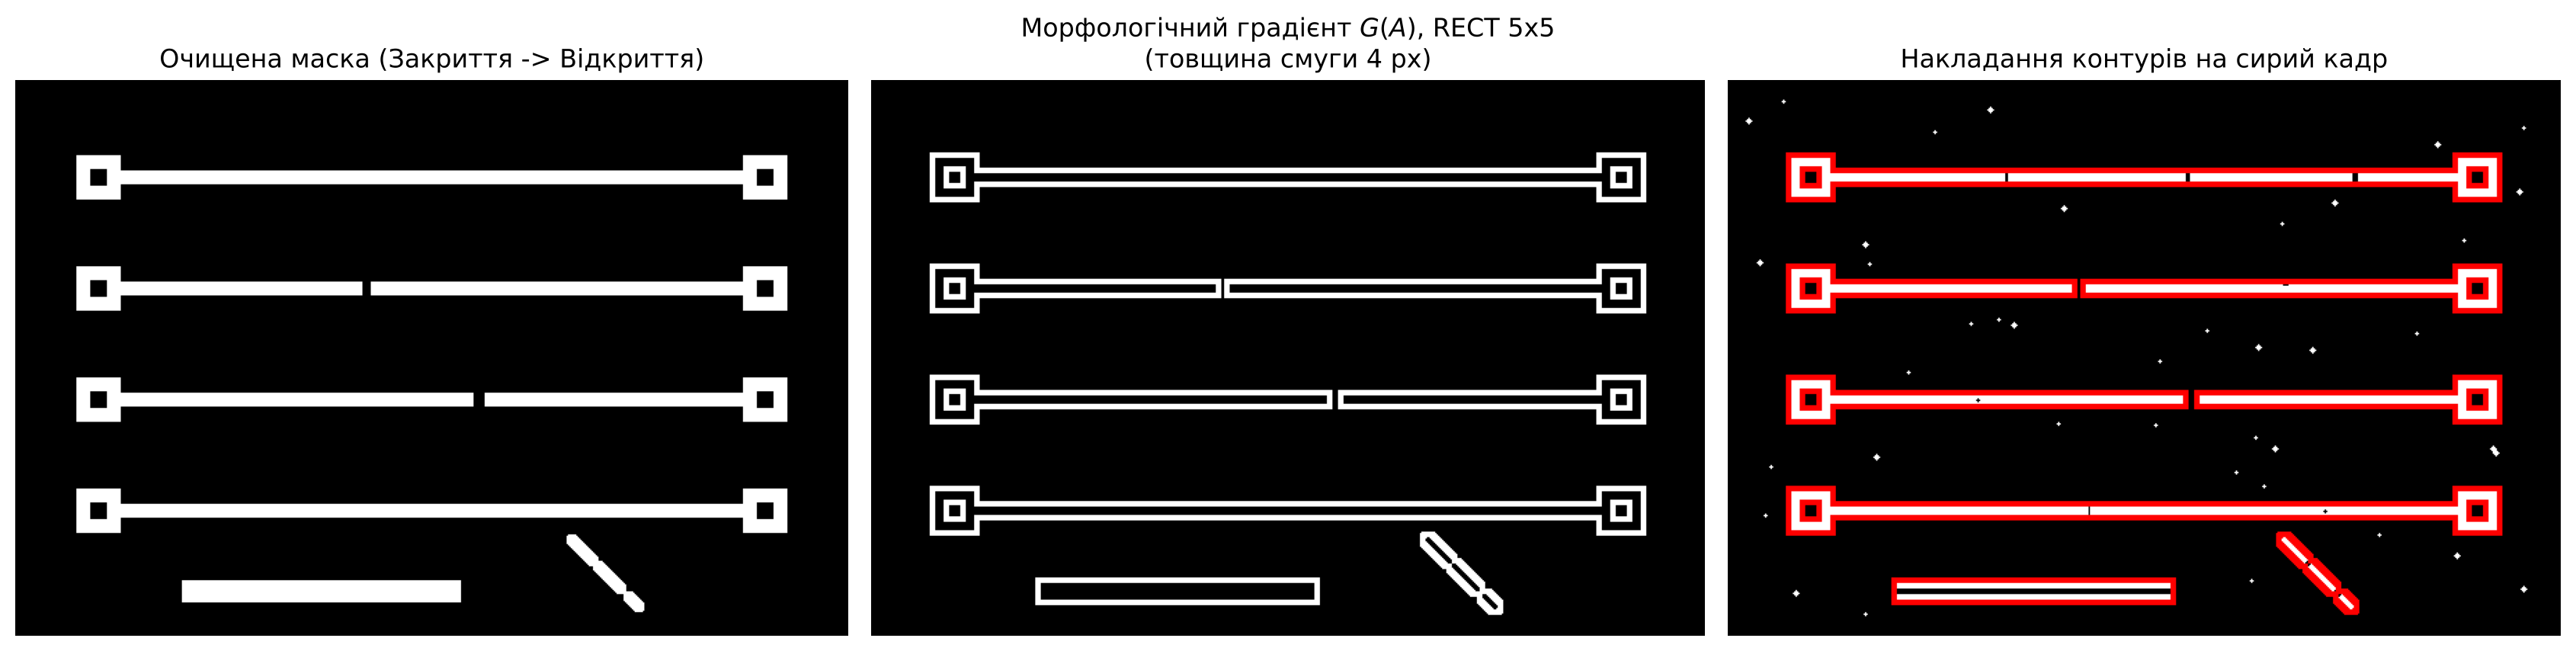

In [6]:
morph_gradient = cv2.morphologyEx(img_pipeline, cv2.MORPH_GRADIENT, SE)
assert np.array_equal(morph_gradient, cv2.subtract(cv2.dilate(img_pipeline, SE), cv2.erode(img_pipeline, SE)))
col = morph_gradient[55:80, 100]                                   # профіль через верхню межу доріжки T1 (y = 65)
band = int(np.count_nonzero(col[:12]))
g3 = cv2.morphologyEx(img_pipeline, cv2.MORPH_GRADIENT, cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3)))
band3 = int(np.count_nonzero(g3[55:70, 100]))
perimeter_px = cv2.countNonZero(morph_gradient)
print(f"Товщина смуги градієнта на прямій межі: RECT {SE_SIZE}x{SE_SIZE} -> {band} px (теорія K - 1 = {SE_SIZE - 1}); RECT 3x3 -> {band3} px (теорія 2)")
print(f"Площа смуги градієнта: {perimeter_px} px; довжина контурів (площа/товщина) ≈ {perimeter_px / band:.0f} px")
assert band == SE_SIZE - 1 and band3 == 2

overlay = cv2.cvtColor(img_binary_raw, cv2.COLOR_GRAY2BGR); overlay[morph_gradient > 0] = (0, 0, 255)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].imshow(img_pipeline, cmap='gray'); axes[0].set_title("Очищена маска (Закриття -> Відкриття)")
axes[1].imshow(morph_gradient, cmap='gray'); axes[1].set_title(f"Морфологічний градієнт $G(A)$, RECT {SE_SIZE}x{SE_SIZE}\n(товщина смуги {band} px)")
axes[2].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)); axes[2].set_title("Накладання контурів на сирий кадр")
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/morphological_grad.png", dpi=200)
plt.show()

## 7. Напівтонова дефектоскопія: Closing -> Black-Hat

На нерівномірно освітленому кадрі виконується закриття ($K=5$, $N_{iter}=1$), і карта дефектів $D=I\bullet B-I$. Перевіряються: збіг із `cv2.MORPH_BLACKHAT` та з `scipy.ndimage.black_tophat`; ідемпотентність закриття та **нульовий Black-Hat від закритого кадру**. Поріг бінаризації карти $D$ визначається трьома способами: фіксований $T=30$ (еталонний приклад лабораторної), метод Оцу та **калібрування за золотою платою** (поріг на рівні $99.99$-го перцентиля карти $D$ бездефектної плати, $+1$). Із калібрування виключається околиця відомого легітимного вузького зазору: він присутній і в золотій платі, є конструктивною особливістю, і якщо його включити, поріг завищується до рівня відгуку на зазор.

**Критерій виявлення.** Частка еталонних пікселів дефекту, що потрапили в маску (перекриття): $\ge80$ % — дефект виявлено (`+`), $30\ldots80$ % — виявлено частково (`~`, відгук є, але закриття заповнило не весь дефект), $<30$ % — пропущено (`-`). Компоненти маски, що не збігаються з жодним дефектом, — хибні спрацювання; окремо рахується спрацювання на легітимному зазорі $4$ px. Піксельні метрики мають допуск $\pm1$ px навколо еталонної маски (краї розмиті).

In [7]:
def black_hat_map(gray, se, n_iter):
    closed = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, se, iterations=n_iter)
    return closed, cv2.subtract(closed, gray)

closed_gray, bh = black_hat_map(img_gray_raw, SE, N_ITER)
bh_cv = cv2.morphologyEx(img_gray_raw, cv2.MORPH_BLACKHAT, SE, iterations=N_ITER)
th_cv = cv2.morphologyEx(img_gray_raw, cv2.MORPH_TOPHAT, SE, iterations=N_ITER)
assert np.array_equal(bh, bh_cv)                                                                        # Closing(I) - I ≡ Black-Hat
assert np.array_equal(cv2.morphologyEx(closed_gray, cv2.MORPH_CLOSE, SE), closed_gray)                  # ідемпотентність закриття
bh_of_closed = cv2.morphologyEx(closed_gray, cv2.MORPH_BLACKHAT, SE)
assert bh_of_closed.max() == 0                                                                          # BH(Closing(I)) = 0
fp_nd = ndimage.black_tophat(img_gray_raw, footprint=SE.astype(bool), mode='nearest')
assert np.array_equal(fp_nd[4:-4, 4:-4], bh[4:-4, 4:-4])

img_golden2, _ = render_gray(clean_mask, seed=13)                              # друга реалізація шуму золотої плати
calib_zone = ~(cv2.dilate(fp_gap, np.ones((9, 9), np.uint8)) > 0)             # виключаємо легітимний вузький зазор (конструктивна особливість)
def calibrate_threshold(se, n_iter):
    _, bh_g = black_hat_map(img_golden, se, n_iter)
    return int(np.ceil(np.percentile(bh_g[calib_zone], 99.99))) + 1, bh_g
def calibrate_diff_threshold(se, n_iter):
    _, b1 = black_hat_map(img_golden, se, n_iter); _, b2 = black_hat_map(img_golden2, se, n_iter)
    return int(np.ceil(np.percentile(np.clip(b2.astype(int) - b1.astype(int), 0, 255), 99.99))) + 1
def diff_map(bh_defect, bh_gold):
    return np.clip(bh_defect.astype(int) - bh_gold.astype(int), 0, 255).astype(np.uint8)
T_CAL, bh_golden = calibrate_threshold(SE, N_ITER)
T_CAL_NAIVE = int(np.ceil(np.percentile(bh_golden, 99.99))) + 1               # без виключення зони зазору (для порівняння)
T_OTSU = float(cv2.threshold(bh, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[0])
T_FIXED = 30

FULL, PART = 0.8, 0.3
all_def = np.zeros((H_IMG, W_IMG), bool)
for d in DEFECTS: all_def |= d["mask"] > 0
all_def_tol = cv2.dilate(all_def.astype(np.uint8), np.ones((3, 3), np.uint8)) > 0
gt_near = cv2.dilate(all_def.astype(np.uint8), np.ones((7, 7), np.uint8)) > 0
fp_near = cv2.dilate(fp_gap, np.ones((7, 7), np.uint8)) > 0

def evaluate_detection(bh_map, thr, min_area=3):
    mask = (bh_map > thr).astype(np.uint8) * 255
    rows = []
    for d in DEFECTS:
        dm = d["mask"] > 0
        ov = float(np.logical_and(mask > 0, dm).sum() / dm.sum())
        rows.append(dict(id=d["id"], kind=d["kind"], overlap=ov, mean_bh=float(bh_map[dm].mean()), status='+' if ov >= FULL else ('~' if ov >= PART else '-')))
    n, lab, st, cen = cv2.connectedComponentsWithStats(mask, connectivity=8)
    fa_noise, fa_pitch = [], []
    for i in range(1, n):
        if st[i, cv2.CC_STAT_AREA] < min_area: continue
        comp = lab == i
        if np.any(comp & gt_near): continue
        (fa_pitch if np.any(comp & fp_near) else fa_noise).append(i)
    tp = int(np.logical_and(mask > 0, all_def).sum()); fn = int(np.logical_and(mask == 0, all_def).sum())
    fp_px = int(np.logical_and(mask > 0, ~all_def_tol & ~(fp_gap > 0)).sum())
    return mask, rows, dict(n_full=sum(r['status'] == '+' for r in rows), n_partial=sum(r['status'] == '~' for r in rows), fa_noise=len(fa_noise), fa_pitch=len(fa_pitch),
                            px_precision=tp / max(tp + fp_px, 1), px_recall=tp / max(tp + fn, 1), n_pixels=int((mask > 0).sum()))

methods = [(f"Фіксований T = {T_FIXED}", T_FIXED), (f"Оцу (T = {T_OTSU:.0f})", T_OTSU), (f"Золота плата (T = {T_CAL})", T_CAL)]
det = {nm: evaluate_detection(bh, thr) for nm, thr in methods}

print("=" * 108)
print("ПЕРЕВІРКИ ТА КАЛІБРУВАННЯ ПОРОГА")
print("=" * 108)
print(f"Black-Hat = Closing - I = cv2.MORPH_BLACKHAT = scipy.ndimage.black_tophat (внутрішня область): збіг повний")
print(f"Ідемпотентність закриття: збігається; max Black-Hat від закритого кадру = {int(bh_of_closed.max())} (тотожний нуль)")
print(f"Золота плата: максимум карти D = {int(bh_golden.max())} (відгук на легітимний зазор 4 px); поріг за всім кадром = {T_CAL_NAIVE}, без зони зазору: 99.99-й перцентиль = {np.percentile(bh_golden[calib_zone], 99.99):.1f} -> T_кал = {T_CAL}; середнє D = {bh_golden[calib_zone].mean():.3f}")
print(f"Карта D дефектної плати: максимум {int(bh.max())}; середнє в зоні дефектів {np.mean([r['mean_bh'] for r in det[methods[2][0]][1]]):.1f}")
print("=" * 108)
size_txt = {"D5": "4x3", "D6": "~3", "D9": "~3"}
print(f"{'ID':<5}{'тип':<12}{'розмір':>8}{'середнє D':>11}" + "".join(f"{'перекриття, % — ' + nm.split(' (')[0][:12]:>34}" for nm, _ in methods))
for i, d in enumerate(DEFECTS):
    sz = size_txt.get(d["id"], str(d.get("w", "")))
    cells_ = "".join(f"{100 * det[nm][1][i]['overlap']:>29.0f} {det[nm][1][i]['status']:>4}" for nm, _ in methods)
    print(f"{d['id']:<5}{d['kind']:<12}{sz:>8}{det[methods[2][0]][1][i]['mean_bh']:11.1f}{cells_}")
print("-" * 108)
print(f"{'Метод':<28}{'повністю':>10}{'частково':>10}{'хибні (шум)':>13}{'вузький зазор':>15}{'піксел. precision (±1 px)':>27}{'піксел. recall':>16}")
for nm, _ in methods:
    s = det[nm][2]
    print(f"{nm:<28}{s['n_full']:10d}{s['n_partial']:10d}{s['fa_noise']:13d}{s['fa_pitch']:15d}{s['px_precision']:27.3f}{s['px_recall']:16.3f}")
print("=" * 108)

ПЕРЕВІРКИ ТА КАЛІБРУВАННЯ ПОРОГА
Black-Hat = Closing - I = cv2.MORPH_BLACKHAT = scipy.ndimage.black_tophat (внутрішня область): збіг повний
Ідемпотентність закриття: збігається; max Black-Hat від закритого кадру = 0 (тотожний нуль)
Золота плата: максимум карти D = 102 (відгук на легітимний зазор 4 px); поріг за всім кадром = 98, без зони зазору: 99.99-й перцентиль = 16.0 -> T_кал = 17; середнє D = 3.927
Карта D дефектної плати: максимум 103; середнє в зоні дефектів 55.3
ID   тип           розмір  середнє D      перекриття, % — Фіксований T               перекриття, % — Оцу      перекриття, % — Золота плата
D1   break              2       84.8                          100    +                          100    +                          100    +
D2   break              3       74.6                          100    +                          100    +                          100    +
D3   break              4       67.5                          100    +                           98    +    

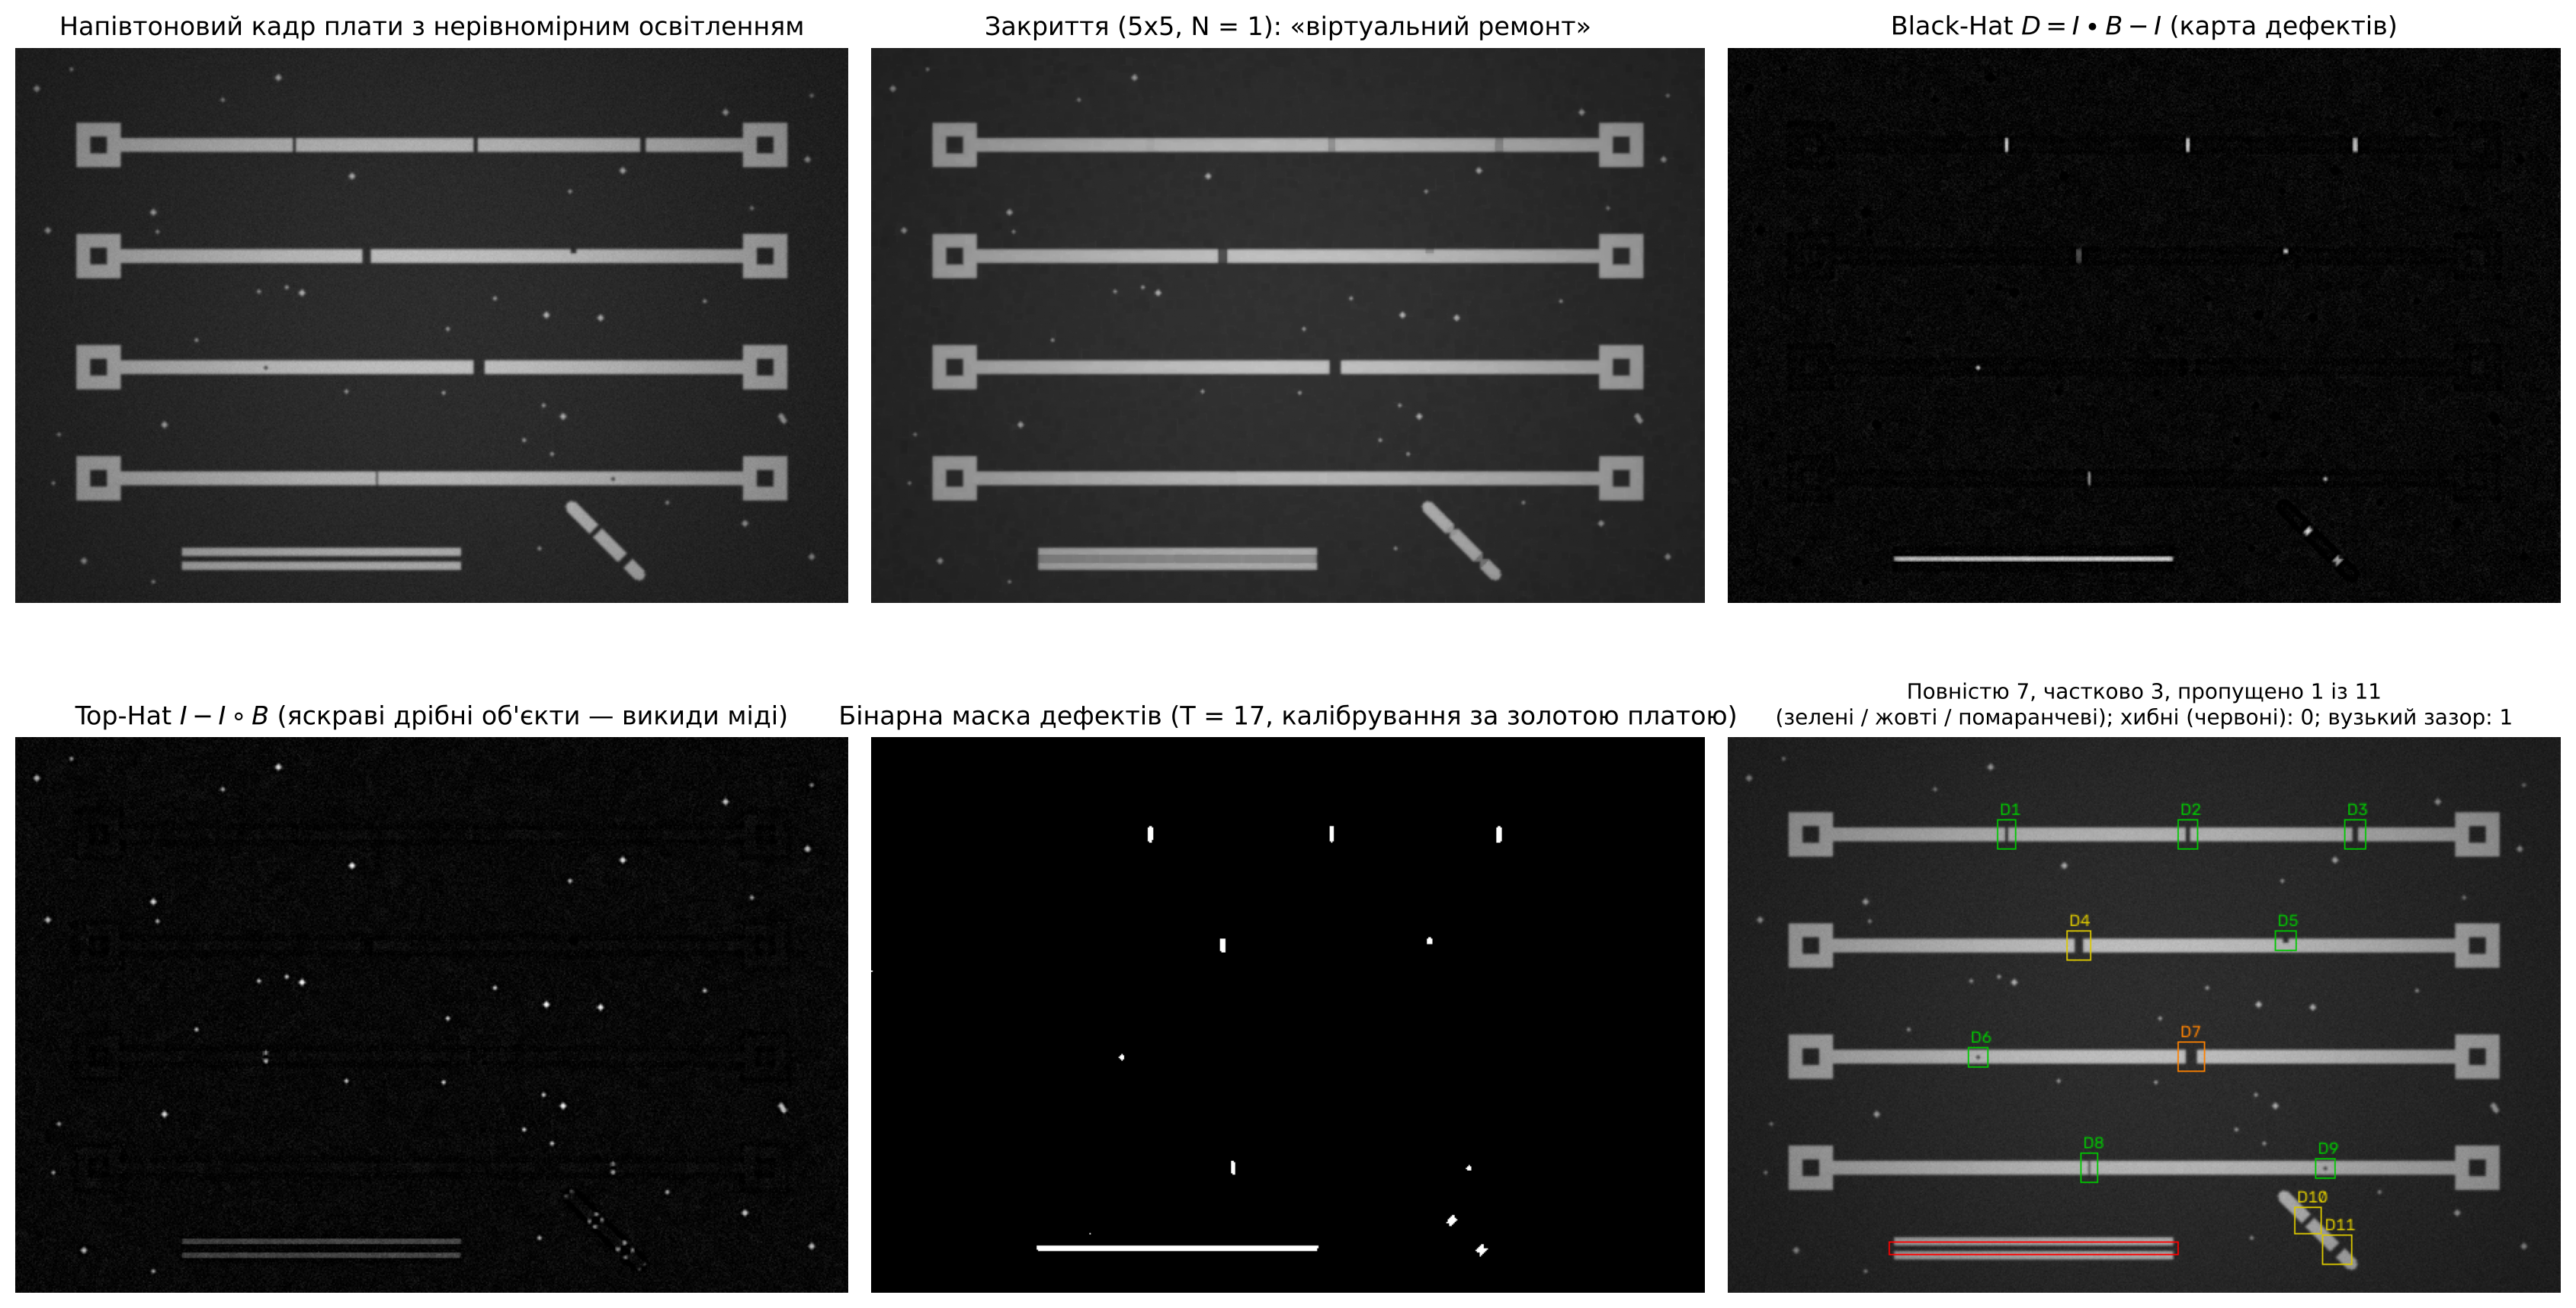

True

In [8]:
mask_cal, rows_cal, st_cal = det[methods[2][0]]
disp = cv2.cvtColor(img_gray_raw, cv2.COLOR_GRAY2BGR)
status_col = {'+': (0, 200, 0), '~': (0, 200, 220), '-': (0, 130, 255)}                         # BGR: виявлено / частково / пропущено
for d, r_ in zip(DEFECTS, rows_cal):
    x, y, w, h = cv2.boundingRect(d["mask"]); col = status_col[r_['status']]
    cv2.rectangle(disp, (x - 6, y - 6), (x + w + 5, y + h + 5), col, 1)
    cv2.putText(disp, d["id"], (x - 4, y - 9), cv2.FONT_HERSHEY_SIMPLEX, 0.4, col, 1, cv2.LINE_AA)
n_c, lab_c, st_c, _ = cv2.connectedComponentsWithStats(mask_cal, connectivity=8)
for i in range(1, n_c):
    if st_c[i, cv2.CC_STAT_AREA] >= 3 and not np.any((lab_c == i) & gt_near):
        x, y, w, h = st_c[i, :4]; cv2.rectangle(disp, (x - 3, y - 3), (x + w + 2, y + h + 2), (0, 0, 255), 1)

fig, axes = plt.subplots(2, 3, figsize=(17, 9.6))
axes[0, 0].imshow(img_gray_raw, cmap='gray', vmin=0, vmax=255); axes[0, 0].set_title("Напівтоновий кадр плати з нерівномірним освітленням")
axes[0, 1].imshow(closed_gray, cmap='gray', vmin=0, vmax=255); axes[0, 1].set_title(f"Закриття ({SE_SIZE}x{SE_SIZE}, N = {N_ITER}): «віртуальний ремонт»")
axes[0, 2].imshow(bh, cmap='gray', vmin=0, vmax=120); axes[0, 2].set_title("Black-Hat $D = I\\bullet B - I$ (карта дефектів)")
axes[1, 0].imshow(th_cv, cmap='gray', vmin=0, vmax=120); axes[1, 0].set_title("Top-Hat $I - I\\circ B$ (яскраві дрібні об'єкти — викиди міді)")
axes[1, 1].imshow(mask_cal, cmap='gray'); axes[1, 1].set_title(f"Бінарна маска дефектів (T = {T_CAL}, калібрування за золотою платою)")
axes[1, 2].imshow(cv2.cvtColor(disp, cv2.COLOR_BGR2RGB))
axes[1, 2].set_title(f"Повністю {st_cal['n_full']}, частково {st_cal['n_partial']}, пропущено {len(DEFECTS) - st_cal['n_full'] - st_cal['n_partial']} із {len(DEFECTS)}\n"
                     f"(зелені / жовті / помаранчеві); хибні (червоні): {st_cal['fa_noise']}; вузький зазор: {st_cal['fa_pitch']}", fontsize=10)
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/tophat_blackhat_comp.png", dpi=200)
plt.show()
cv2.imwrite("data/closing_result.png", closed_gray); cv2.imwrite("data/blackhat_map.png", bh); cv2.imwrite("data/defect_mask_variant2.png", mask_cal)

## 8. Вплив форми, розміру ядра та кількості ітерацій

Для кожної конфігурації $(B,N_{iter})$ повторюється повний цикл у двох режимах:

- **(а) пряме порогування карти $D$** з калібруванням за золотою платою (як у розділі 7) — практичний режим;
- **(б) із відніманням золотої плати**: $D_{diff}=\max(D_{defect}-D_{golden},0)$, поріг калібрується за різницею двох бездефектних плат з різним шумом. Структурні відгуки, які присутні в обох платах, скорочуються, тому режим ізолює саме **геометричну здатність елемента заповнювати дефект**.

Розглядаються: `RECT` $3\times3$, $5\times5$ (варіант), $7\times7$; `CROSS` та `ELLIPSE` $5\times5$; `RECT` $5\times5$ з $N_{iter}=2$ (еквівалент $9\times9$). Додатково рахується кількість «структурних» пікселів золотої плати ($D>25$ поза зоною зазору): це відгук закриття на вогнуті кути та інші легітимні елементи самої розкладки.

(а) ПРЯМЕ ПОРОГУВАННЯ КАРТИ D (калібрування за золотою платою)
Конфігурація               T   D1   D2   D3   D4   D5   D6   D7   D8   D9  D10  D11  повн.  част.  хибні  зазор  precision   recall  структ. px
RECT 3x3                  16    +    ~    ~    -    ~    +    -    +    +    ~    -      4      4      0      1      0.936    0.254           0
RECT 5x5 (варіант 2)      17    +    +    +    ~    +    +    -    +    +    ~    ~      7      3      0      1      0.970    0.645           0
RECT 7x7                  18    +    +    +    +    +    +    ~    +    +    ~    ~      8      3      0      1      0.425    0.873           0
CROSS 5x5                 76    ~    -    -    -    -    -    -    -    -    -    -      0      1      0      4      0.579    0.064         251
ELLIPSE 5x5               55    +    +    ~    -    ~    +    -    ~    -    ~    -      3      4      0      1      0.925    0.283         124
RECT 5x5, N = 2           18    +    +    +    +    +    +    +    +    +

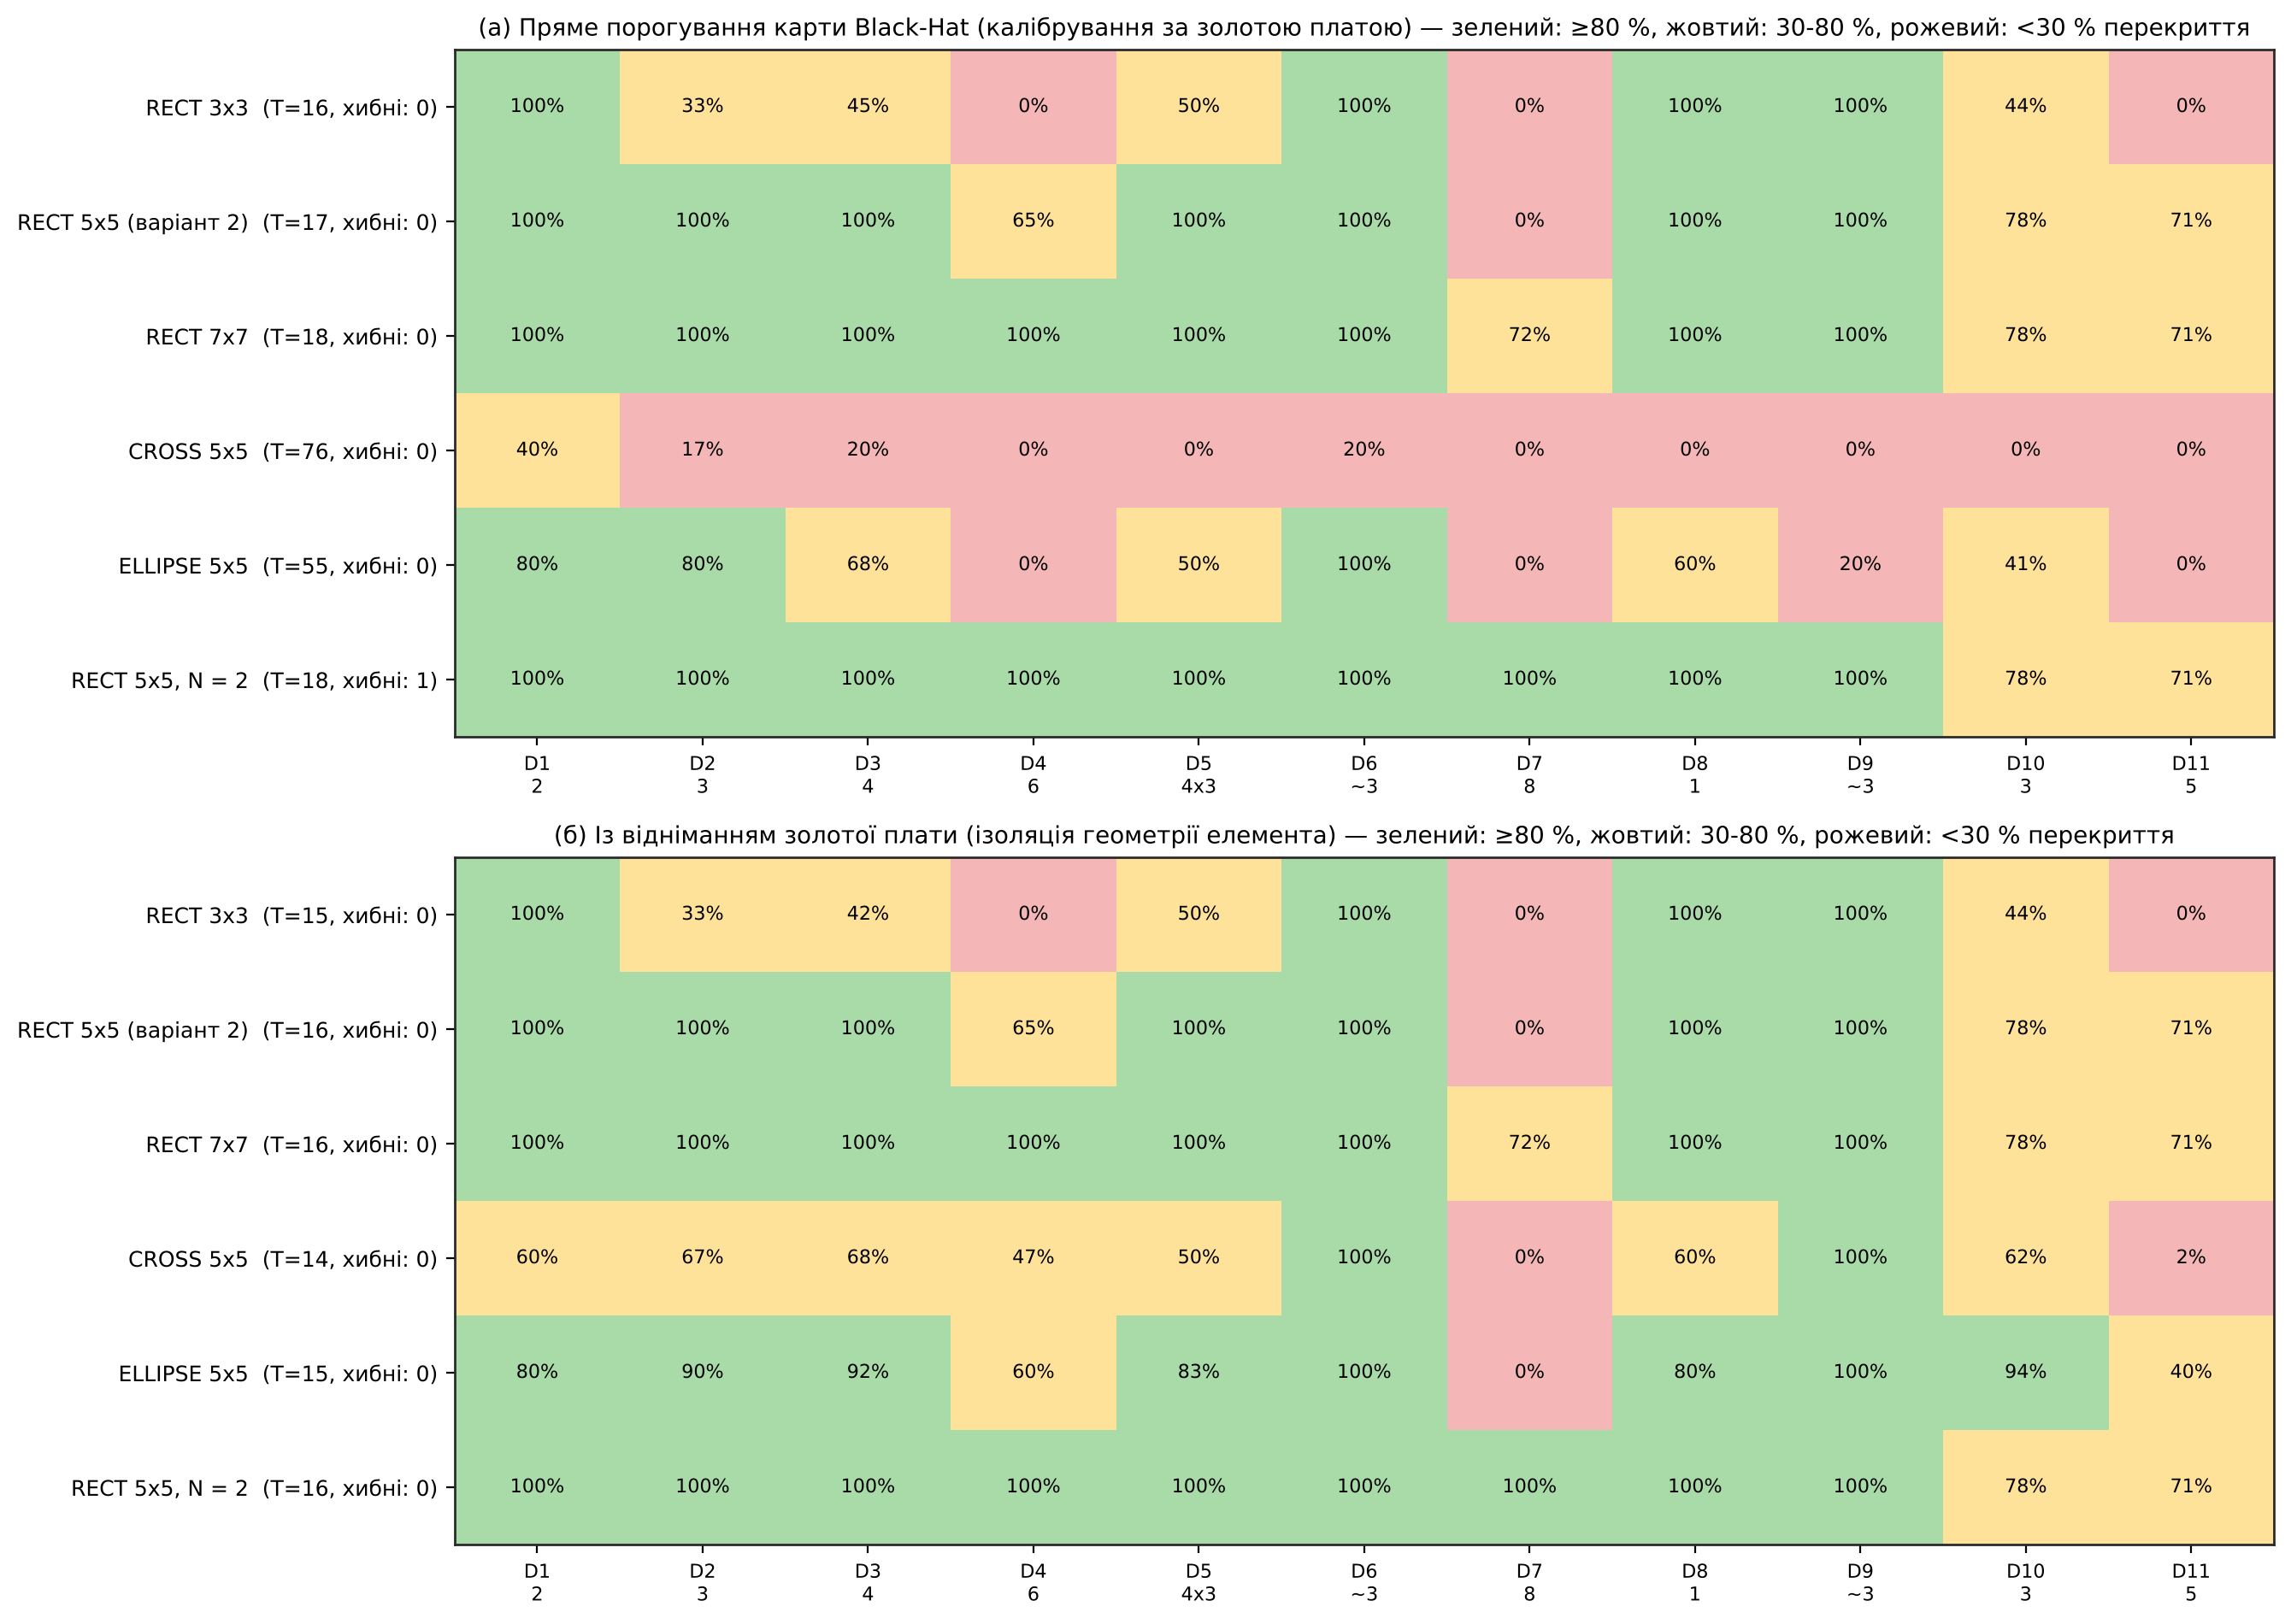

In [9]:
configs = [("RECT 3x3", cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3)), 1), ("RECT 5x5 (варіант 2)", se_rect, 1), ("RECT 7x7", cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7)), 1),
           ("CROSS 5x5", se_cross, 1), ("ELLIPSE 5x5", se_ellipse, 1), ("RECT 5x5, N = 2", se_rect, 2)]
study = {}
for nm, se, n_it in configs:
    thr, bh_g = calibrate_threshold(se, n_it)
    _, bh_d = black_hat_map(img_gray_raw, se, n_it)
    thr_diff = calibrate_diff_threshold(se, n_it)
    _, rows_a, st_a = evaluate_detection(bh_d, thr)
    _, rows_b, st_b = evaluate_detection(diff_map(bh_d, bh_g), thr_diff)
    study[nm] = dict(T=thr, rows=rows_a, stats=st_a, T_diff=thr_diff, rows_diff=rows_b, stats_diff=st_b, structural_px=int((bh_g[calib_zone] > 25).sum()))

hdr = lambda: f"{'Конфігурація':<24}{'T':>4}" + "".join(f"{d['id']:>5}" for d in DEFECTS) + f"{'повн.':>7}{'част.':>7}{'хибні':>7}{'зазор':>7}{'precision':>11}{'recall':>9}"
print("=" * 130); print("(а) ПРЯМЕ ПОРОГУВАННЯ КАРТИ D (калібрування за золотою платою)"); print("=" * 130); print(hdr() + f"{'структ. px':>12}")
for nm, _, _ in configs:
    s = study[nm]; sts = s['stats']
    print(f"{nm:<24}{s['T']:4d}" + "".join(f"{r['status']:>5}" for r in s['rows']) + f"{sts['n_full']:>7}{sts['n_partial']:>7}{sts['fa_noise']:>7}{sts['fa_pitch']:>7}{sts['px_precision']:>11.3f}{sts['px_recall']:>9.3f}{s['structural_px']:>12}")
print("\n" + "=" * 130); print("(б) ІЗ ВІДНІМАННЯМ ЗОЛОТОЇ ПЛАТИ (ізоляція геометрії елемента)"); print("=" * 130); print(hdr())
for nm, _, _ in configs:
    s = study[nm]; sts = s['stats_diff']
    print(f"{nm:<24}{s['T_diff']:4d}" + "".join(f"{r['status']:>5}" for r in s['rows_diff']) + f"{sts['n_full']:>7}{sts['n_partial']:>7}{sts['fa_noise']:>7}{sts['fa_pitch']:>7}{sts['px_precision']:>11.3f}{sts['px_recall']:>9.3f}")
print("=" * 130)
print("Розмір дефектів: " + ", ".join(f"{d['id']}: {size_txt.get(d['id'], str(d.get('w', '')))}" for d in DEFECTS))

cmap3 = ListedColormap(['#f4b6b6', '#ffe29a', '#a8dba8'])
code_of = {'-': 0, '~': 1, '+': 2}
fig, axes = plt.subplots(2, 1, figsize=(13.5, 9.6))
for ax, key, ttl in [(axes[0], 'rows', "(а) Пряме порогування карти Black-Hat (калібрування за золотою платою)"), (axes[1], 'rows_diff', "(б) Із відніманням золотої плати (ізоляція геометрії елемента)")]:
    mat = np.array([[code_of[r['status']] for r in study[nm][key]] for nm, _, _ in configs])
    ax.imshow(mat, cmap=cmap3, aspect='auto', vmin=0, vmax=2)
    for i, (nm, _, _) in enumerate(configs):
        for j, r_ in enumerate(study[nm][key]):
            ax.text(j, i, f"{100 * r_['overlap']:.0f}%", ha='center', va='center', fontsize=8)
    ax.set_xticks(range(len(DEFECTS))); ax.set_xticklabels([f"{d['id']}\n{size_txt.get(d['id'], str(d.get('w', '')))}" for d in DEFECTS], fontsize=8)
    ax.set_yticks(range(len(configs)))
    ax.set_yticklabels([f"{nm}  (T={study[nm]['T' if key == 'rows' else 'T_diff']}, хибні: {study[nm]['stats' if key == 'rows' else 'stats_diff']['fa_noise']})" for nm, _, _ in configs], fontsize=9)
    ax.set_title(ttl + " — зелений: ≥80 %, жовтий: 30-80 %, рожевий: <30 % перекриття", fontsize=10)
plt.tight_layout()
plt.savefig("figures/se_study.png", dpi=200)
plt.show()

## 9. Зведена таблиця та експорт результатів

In [10]:
table_rows = []
for i, d in enumerate(DEFECTS):
    table_rows.append(dict(id=d['id'], kind=d['kind'], size=size_txt.get(d['id'], d.get('w', '')), area_px=cv2.countNonZero(d['mask']),
                           mean_bh=det[methods[2][0]][1][i]['mean_bh'], overlap_calibrated=det[methods[2][0]][1][i]['overlap'],
                           status_fixed=det[methods[0][0]][1][i]['status'], status_otsu=det[methods[1][0]][1][i]['status'],
                           status_calibrated=det[methods[2][0]][1][i]['status']))
with open("data/defects_table.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(table_rows[0].keys())); w.writeheader(); w.writerows(table_rows)
with open("data/se_study.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f); w.writerow(["config", "mode", "threshold"] + [d['id'] for d in DEFECTS] + ["full", "partial", "false_alarms_noise", "false_alarms_pitch", "px_precision", "px_recall", "structural_px"])
    for nm, _, _ in configs:
        s_ = study[nm]
        for mode, key_r, key_s, key_t in [("direct", 'rows', 'stats', 'T'), ("golden_difference", 'rows_diff', 'stats_diff', 'T_diff')]:
            st_ = s_[key_s]
            w.writerow([nm, mode, s_[key_t]] + [r['status'] for r in s_[key_r]] + [st_['n_full'], st_['n_partial'], st_['fa_noise'], st_['fa_pitch'], st_['px_precision'], st_['px_recall'], s_['structural_px']])
cv2.imwrite("data/binary_opened.png", img_opened); cv2.imwrite("data/binary_closed.png", img_closed); cv2.imwrite("data/binary_pipeline.png", img_pipeline)
cv2.imwrite("data/binary_eroded.png", img_eroded); cv2.imwrite("data/binary_dilated.png", img_dilated); cv2.imwrite("data/morphological_gradient.png", morph_gradient)

results = dict(
    variant=2, params=dict(shape="MORPH_RECT", size=SE_SIZE, n_iter=N_ITER, pipeline="Closing -> Black-Hat"),
    structuring_elements=dict(rect=int(se_rect.sum()), cross=int(se_cross.sum()), ellipse=int(se_ellipse.sum())),
    binary=dict(area=dict(raw=area_orig, eroded=area_er, dilated=area_di, opened=cv2.countNonZero(img_opened), closed=cv2.countNonZero(img_closed),
                          pipeline=cv2.countNonZero(img_pipeline), clean=cv2.countNonZero(clean_mask)),
                iou_with_clean=dict(raw=iou(A, clean_mask), opened=iou(img_opened, clean_mask), closed=iou(img_closed, clean_mask), pipeline=iou(img_pipeline, clean_mask)),
                iou_without_pitch_zone=dict(raw=iou_excl(A, clean_mask), opened=iou_excl(img_opened, clean_mask), closed=iou_excl(img_closed, clean_mask), pipeline=iou_excl(img_pipeline, clean_mask)),
                components=comps, gradient_band_px=band, gradient_band_3x3_px=band3),
    blackhat=dict(thresholds=dict(fixed=T_FIXED, otsu=T_OTSU, calibrated=T_CAL, percentile_naive=T_CAL_NAIVE, percentile_outside_pitch=float(np.percentile(bh_golden[calib_zone], 99.99))), golden_max=int(bh_golden.max()), bh_of_closed_max=int(bh_of_closed.max()),
                  methods={nm: det[nm][2] for nm, _ in methods}),
    se_study={nm: dict(T=study[nm]['T'], status=[r['status'] for r in study[nm]['rows']], stats=study[nm]['stats'], T_diff=study[nm]['T_diff'], status_diff=[r['status'] for r in study[nm]['rows_diff']], stats_diff=study[nm]['stats_diff'], structural_px=study[nm]['structural_px']) for nm, _, _ in configs},
    defects=table_rows,
)
with open("data/results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=1, default=lambda o: bool(o) if isinstance(o, (np.bool_,)) else float(o))
print("Готово: figures/, data/")

Готово: figures/, data/


## Висновки

1. **Елементарні операції та структурні елементи.** Сцена $600\times400$ містить мідь еталона $28060$ px (7 зв'язних компонентів); після внесення 11 дефектів і викидів міді — $28058$ px і $54$ компоненти. Для елемента варіанта 2 (`MORPH_RECT` $5\times5$, 25 одиниць) ерозія зменшує площу з $28058$ до $15648$ px ($-44.2$ %, $17$ компонентів), діляція збільшує до $42074$ px ($+50.0$ %, $47$ компонентів). Реалізація `cv2` збігається зі `scipy.ndimage`, двоїстість ерозії та діляції виконується, а $N_{iter}=2$ для $5\times5$ збігається з одним елементом $9\times9$ (формула $(K-1)N_{iter}+1$). Хрестоподібний і еліптичний елементи $5\times5$ мають лише 9 та 17 одиниць із 25, тому їхня дія слабша і геометрично інша.
2. **Відкриття та закриття.** Відкриття видаляє викиди міді (IoU з еталоном $0.9757\to0.9852$), але розриви доріжок лишає, а в місцях пор D6 і D9 розрізає доріжку на фрагменти (17 компонентів). Закриття усуває розриви вужчі за $K=5$ px та пори, проте залишає викиди міді (47 компонентів) і зливає дві паралельні доріжки з легітимним зазором $4$ px, тому IoU $0.9550$ (без зони зазору — $0.9810$). Конвеєр «Закриття $\to$ Відкриття» дає IoU $0.9663$ ($0.9936$ без зони зазору). Розрізи, що усуваються закриттям $5\times5$: 6 з 8 (D1, D2, D3, D8, D10, D11); лишаються D4 ($6$ px) і D7 ($8$ px). Кількість компонентів після конвеєра $8$ збігається з прогнозом $7+2-1=8$ (7 еталонних, 2 нерозірвані розриви, одне хибне злиття зазору).
3. **Морфологічний градієнт.** Товщина смуги на прямій межі дорівнює $K-1$: $4$ px для $5\times5$ і $2$ px для $3\times3$ (збіг із теорією); площа смуги $22324$ px, оцінка довжини контурів $\approx5581$ px. Градієнт є різницею діляції та ерозії, тому товщина контуру задається розміром елемента, а не самим зображенням.
4. **Ідемпотентність і суть конвеєра варіанта 2.** Закриття ідемпотентне: максимум Black-Hat від уже закритого кадру дорівнює $0$. Отже, `Closing -> Black-Hat` тотожний одному Black-Hat $D=I\bullet B-I$. Він збігається з `cv2.MORPH_BLACKHAT` і `scipy.ndimage.black_tophat` (у внутрішній області). Закриття $5\times5$ заповнює розрив через усю ширину доріжки при $w\le K-1=4$ px, діагональний розрив — при $L<e_B/\sqrt2=5.66$ px (RECT), $4.24$ (ELLIPSE), $2.83$ (CROSS). Top-Hat натомість виділяє яскраві дрібні об'єкти — викиди міді, а не розриви.
5. **Виявлення розривів: порогування карти $D$.** Максимум карти $D$ дефектної плати $103$, середнє в зоні дефектів $55.3$. Для кожного дефекту перекриття маски порога з маскою дефекту подано трьома статусами: «+» ($\ge80$ %), «~» ($30\text{-}80$ %), «-» ($<30$ %). Калібрування за золотою платою (99.99-й перцентиль без зони зазору, $+1$) дає $T=17$; без виключення зони зазору той самий спосіб дав би $T=98$, бо легітимний зазор $4$ px сам дає відгук до $102$. Результати для $5\times5$:

   | Метод порога | повністю «+» | частково «~» | пропущено «-» | хибні (шум) | хибний зазор | піксел. recall |
   |---|---|---|---|---|---|---|
   | фіксований $T=30$ | 7 | 3 | 1 | 0 | 1 | $0.564$ |
   | Оцу ($T=39$) | 7 | 2 | 2 | 0 | 1 | $0.477$ |
   | золота плата ($T=17$) | 7 | 3 | 1 | 0 | 1 | $0.645$ |

   Розриви $1\ldots4$ px, виріз D5 і пори D6, D9 виявляються повністю всіма методами. D4 ($6$ px) лежить на межі розмірів: середнє $D=20.3$ лише трохи перевищує $T=17$, тому Оцу його втрачає ($0$ %), фіксований поріг дає $37$ %, калібрований — $65$ %. D7 ($8$ px) не виявляється жодним методом (середнє $D=3.4$): закриття $5\times5$ його не заповнює, тож Black-Hat не бачить цього розриву. Діагональні D10 ($3$ px) та D11 ($5$ px) виявляються лише частково ($78$ та $71$ %), хоча обидва нижчі за межу $5.66$ px.
6. **Вплив форми та розміру елемента.** Дослідження $6$ конфігурацій у двох режимах: (а) пряме порогування з калібруванням за золотою платою; (б) із відніманням золотої плати, що виключає відгук елемента на легітимну геометрію.

   | Конфігурація | (а): повн./част., хибні шум / зазор | (б): повн./част., хибні шум / зазор | recall (б) |
   |---|---|---|---|
   | RECT $3\times3$ | 4 / 4, 0 / 1 | 4 / 4, 0 / 0 | $0.251$ |
   | RECT $5\times5$ (варіант 2) | 7 / 3, 0 / 1 | 7 / 3, 0 / 0 | $0.645$ |
   | RECT $7\times7$ | 8 / 3, 0 / 1 | 8 / 3, 0 / 0 | $0.873$ |
   | CROSS $5\times5$ | 0 / 1, 0 / 4 | 2 / 7, 0 / 0 | $0.376$ |
   | ELLIPSE $5\times5$ | 3 / 4, 0 / 1 | 8 / 2, 0 / 0 | $0.564$ |
   | RECT $5\times5$, $N_{iter}=2$ | 9 / 2, 1 / 1 | 9 / 2, 0 / 0 | $0.936$ |

   Збільшення елемента (RECT $7\times7$ або $N_{iter}=2$) піднімає чутливість: D4 виявляється на $100$ %, а за $N_{iter}=2$ (еквівалент $9\times9$, заповнює розриви до $8$ px) повністю виявляється і D7. Ціна — відгук на легітимну геометрію: у режимі (а) піксельна precision падає з $0.970$ ($5\times5$) до $0.425$ ($7\times7$) і $0.434$ ($N_{iter}=2$, плюс одна хибна ділянка шуму), а в режимі (б) вертається до $0.984$ та $0.973$, тобто ці хибні пікселі — відгук елемента на структуру плати, а не на шум (віднімання еталона їх усуває). Малий елемент $3\times3$ заповнює лише розриви до $2$ px, тож пропускає D4, D7 і D11. Хрестоподібний елемент у режимі (а) непридатний: на золотій платі $251$ піксель поза зоною зазору має $D>25$ (еліпс — $124$, прямокутні елементи — $0$), що змушує обрати $T=76$, і майже всі дефекти пропускаються; віднімання золотої плати повертає $T=14$ і $2$ повних та $7$ часткових виявлень. Еліпс у режимі (б) дає найкраще перекриття діагонального D10 ($94$ %), але гірше за RECT на D11 ($40$ %).
7. **Золота плата.** Віднімання відгуку еталонної плати в усіх конфігураціях обнуляє хибний сигнал від легітимного зазору $4$ px (з $1$ до $0$) і лишає в карті відмінності, що походять від дефектів, а не від геометрії плати: порівняння елементів у режимі (б) коректніше, ніж у режимі (а). Це можливо лише коли еталонна плата доступна і кадри сумістні; в іншому випадку лишається тільки калібрування порога за зоною без структурних особливостей, а такі особливості (як зазор $4$ px) потрібно додатково маскувати.
8. **Практичний висновок.** Для варіанта 2 (`MORPH_RECT` $5\times5$, $N_{iter}=1$, `Closing -> Black-Hat`) метод надійно виявляє розриви шириною $1\ldots4$ px, виріз та пори ($7$ з $11$ повністю, $0$ хибних на шумі), але не бачить розриву $8$ px і лише частково бачить $6$ px та діагональні розриви, а легітимний зазор $4$ px дає хибне спрацювання. Для розривів до $8$ px підходить $N_{iter}=2$ (або елемент $9\times9$) ціною відгуку на геометрію, який усувається відніманням золотої плати. Чутливість до розривів задається саме розміром елемента: розрив $w$ виявляється, якщо $w\le(K-1)N_{iter}$, тому $K-1$ має бути не меншим за ширину найбільшого розриву, який потрібно виявити, і меншим за найвужчий легітимний зазор. У цій платі обидві вимоги несумісні (зазор $4$ px вужчий за розрив D4 у $6$ px), тому без віднімання золотої плати хибне спрацювання на зазорі неминуче.

## Контрольні питання

**1. Що таке структуруючий елемент (ядро) у математичній морфології, і як його форма (прямокутник, хрест, еліпс) впливає на результат геометричної обробки?**

* **Визначення:** Структуруючий елемент (ядро або примітив) — це невелика матриця заданої форми та розміру з визначеною опорною точкою (зазвичай у центрі), яка використовується як «зонд» для взаємодії з пікселями зображення під час морфологічних перетворень.
* **Вплив форми ядра:**
* **Прямокутник (квадрат):** Впливає однаково за ортогональними та діагональними напрямками (8-зв'язність), формує чіткі прямі кути, добре зберігає горизонтальні й вертикальні межі, але «оквадрачує» округлі об'єкти.
* **Хрест:** Враховує лише горизонтальний і вертикальний напрямки (4-зв'язність), ігноруючи діагональні сусідні пікселі. Завдяки цьому він краще зберігає гострі кути, тонкі діагональні лінії та менше спотворює дрібні деталі порівняно з прямокутником такого ж габариту.
* **Еліпс (диск/коло):** Забезпечує ізотропну (рівномірну в усіх напрямках) обробку, м'яко згладжує контури та зберігає природну округлу геометрію об'єктів без створення штучних кутових артефактів.



---

**2. У чому полягає математична та геометрична відмінність між операціями ерозії ($A \ominus B$) та діляції ($A \oplus B$) над бінарними множинами?**

* **Ерозія ($A \ominus B$):**
* *Математично:* Множина всіх точок $z$, для яких структуруючий елемент $B$, зсунутий у точку $z$, повністю міститься всередині множини об'єкта $A$:

$$A \ominus B = \{ z \mid (B)_z \subseteq A \}$$


* *Геометрично:* Звужує (витончує) світлі об'єкти, зрізаючи зовнішній шар пікселів по контуру, видаляє дрібні шумові викиди та розриває тонкі перемички, менші за розмір ядра $B$.


* **Діляція ($A \oplus B$):**
* *Математично:* Множина всіх точок $z$, для яких відображений відносно початку координат елемент $\hat{B}$, зсунутий у точку $z$, має непорожній перетин із множиною $A$:

$$A \oplus B = \{ z \mid (\hat{B})_z \cap A \neq \emptyset \}$$


* *Геометрично:* Розширює (потовщує) світлі об'єкти, нарощуючи їхній зовнішній контур, заповнює дрібні отвори й тріщини всередині фігур та об'єднує близько розташовані фрагменти.



---

**3. Чому операції морфологічного відкриття та закриття називають ідемпотентними, і в яких випадках їх застосовують замість окремих ерозій та діляцій?**

* **Ідемпотентність:** Операції відкриття ($A \circ B$) та закриття ($A \bullet B$) є ідемпотентними, оскільки їх повторне застосування тим самим структуруючим елементом не змінює вже отриманий результат:

$$(A \circ B) \circ B = A \circ B, \qquad (A \bullet B) \bullet B = A \bullet B$$



Після першого проходу всі деталі, менші за ядро $B$, уже усунуті або заповнені, а контури узгоджені з формою $B$, тому подальші застосування не дають нового ефекту.
* **Випадки застосування замість окремих ерозій та діляцій:** Окремі ерозія або діляція незворотно зменшують або збільшують площу та лінійні розміри об'єктів. Відкриття ($A \circ B = (A \ominus B) \oplus B$) і закриття ($A \bullet B = (A \oplus B) \ominus B$) застосовують тоді, коли потрібно **очистити зображення від дефектів без суттєвої зміни загального масштабу та розмірів основних об'єктів**:
* *Відкриття* — для видалення дрібного світлого шуму («сіль»), тонких виступів і розділення злиплих об'єктів зі збереженням їхніх початкових розмірів.
* *Закриття* — для заповнення дрібних темних отворів («перець»), вузьких тріщин і розривів контуру без роздування зовнішніх меж фігур.



---

**4. Яким чином морфологічне відкриття дозволяє розділити два частково перекриті круглі об'єкти, з'єднані тонким перешийком?**

Морфологічне відкриття послідовно виконує ерозію та діляцію одним і тим самим структуруючим елементом $B$: $A \circ B = (A \ominus B) \oplus B$. Якщо обрати ядро (наприклад, диск), діаметр якого **більший за товщину перешийка, але менший за діаметр основних круглих об'єктів**, процес відбувається у два етапи:

1. **Ерозія ($A \ominus B$):** Структуруючий елемент не поміщається в межах вузького перешийка, тому пікселі перемички повністю стираються — зв'язок між фігурами розривається. Основні круглі об'єкти при цьому лише зменшуються в радіусі на величину радіуса ядра, але зберігаються.
2. **Діляція ($\oplus B$):** Зменшені ядра круглих об'єктів відновлюються до своїх вихідних розмірів, тоді як розірваний перешийок уже не відновлюється, оскільки між об'єктами утворився розрив, більший за розмір елемента $B$.

---

**5. Як формується морфологічний градієнт, і чим внутрішній та зовнішній градієнти відрізняються від повного градієнта $G(A) = (A \oplus B) - (A \ominus B)$?**

* **Формування повного (симетричного) градієнта:** Обчислюється як попіксельна різниця між результатом діляції та результатом ерозії: $G(A) = (A \oplus B) - (A \ominus B)$. Він виділяє контурну смугу, розташовану симетрично по обидва боки від початкової межі об'єкта.
* **Відмінності внутрішнього та зовнішнього градієнтів:**
* **Внутрішній градієнт** $G_{\text{int}}(A) = A - (A \ominus B)$ — різниця між вихідним зображенням і результатом ерозії. Виділяє контур, який лежить **суворо всередині** самого об'єкта (належить пікселям переднього плану) і має вдвічі меншу товщину порівняно з повним градієнтом.
* **Зовнішній градієнт** $G_{\text{ext}}(A) = (A \oplus B) - A$ — різниця між результатом діляції та вихідним зображенням. Виділяє контур, який лежить **суворо зовні** об'єкта (належить пікселям фону, безпосередньо прилягаючи до його межі), і також є тоншим за повний градієнт.



---

**6. Опишіть принцип функціонування перетворення «білий капелюх» (White Top-Hat). Чому воно ефективно усуває повільні градієнтні перепади фонової яскравості?**

* **Принцип функціонування:** Перетворення White Top-Hat визначається як різниця між вихідним напівтоновим зображенням $f$ та результатом його морфологічного відкриття:

$$T_{\text{hat}}(f) = f - (f \circ B)$$



Операція відкриття $f \circ B$ зрізає всі локальні світлі піки та дрібні світлі об'єкти, менші за розмір ядра $B$, формуючи оцінку плавного фону. Подальше віднімання відкритого зображення від оригіналу залишає лише ці виділені дрібні світлі деталі.
* **Причина усунення повільних градієнтів фону:** Плавні перепади фонової яскравості (нерівномірне освітлення) мають значно більший просторовий масштаб, ніж розмір структуруючого елемента $B$. Через це відкриття $f \circ B$ практично не змінює повільний градієнт фону, і він однаково присутній як у $f$, так і в $(f \circ B)$. Під час віднімання $f - (f \circ B)$ фонова складова взаємно скорочується, вирівнюючи яскравість фону.

---

**7. У чому полягає сутність перетворення «чорний капелюх» (Black-Hat), і чому розмір структуруючого елемента $B$ при цьому повинен перевищувати геометричну товщину темних тріщин?**

* **Сутність перетворення:** Перетворення Black-Hat визначається як різниця між результатом морфологічного закриття зображення $f \bullet B$ та вихідним зображенням $f$:

$$B_{\text{hat}}(f) = (f \bullet B) - f$$



Закриття заповнює локальні темні провали (тріщини, пори, тонкі темні лінії) яскравістю навколишнього світлого фону, а віднімання оригіналу $f$ перетворює ці темні дефекти на яскраві світлі об'єкти на темному вирівняному фоні.
* **Необхідність перевищення товщини тріщин розміром ядра $B$:** На першому кроці закриття виконується діляція $f \oplus B$, яка нарощує світлі краї навколо темної тріщини назустріч один одному. Щоб протилежні світлі стінки тріщини зімкнулися і повністю заповнили її просвіт фоновим значенням, розмір структуруючого елемента $B$ має бути більшим за геометричну ширину тріщини. Якщо $B$ буде меншим або рівним товщині тріщини, ядро вільно поміститься всередині неї, закриття не заповнить дефект, і різниця $(f \bullet B) - f$ не виділить тріщину.